In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install psycopg2-binary

Access is denied.


In [3]:
import sys
print(sys.executable)

C:\ProgramData\anaconda3\python.exe


In [4]:
!{sys.executable} -m pip install psycopg2-binary --user

In [5]:
import psycopg2



In [6]:

conn = psycopg2.connect(
    host="localhost",
    database="upi_reliability_analytics",
    user="postgres",
    password="Aa@shu2026",
    port="5433"
)

print("database connected successfully")

database connected successfully


In [7]:
query = """
select *
from transactions;
"""

df_transactions = pd.read_sql(query, conn)

df_transactions.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\1994992412.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_transactions = pd.read_sql(query, conn)


,transaction_id,user_id,merchant_id,bank_id,device_id,location_id,transaction_date,transaction_amount,transaction_status,failure_reason_id,payment_channel,is_retry
0,1,2222,310,12,519,19,2025-06-14 22:41:52.572596,31701.56,success,NaN,qr,False
1,2,3991,1105,9,8157,3,2025-01-07 11:49:36.221277,25565.43,success,NaN,collect_request,False
2,3,16,1597,13,8238,3,2025-06-07 04:59:32.594617,37309.19,success,NaN,upi_id,False
3,4,7934,124,14,5661,17,2025-10-27 15:27:12.347426,26659.71,success,NaN,upi_id,False
4,7,8162,477,3,10811,3,2025-04-26 19:51:33.652314,20582.12,success,NaN,upi_id,False


In [8]:
print("rows:", df_transactions.shape[0])
print("columns:", df_transactions.shape[1])

rows: 100000
columns: 12


In [9]:
df_transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction_id      100000 non-null  int64         
 1   user_id             100000 non-null  int64         
 2   merchant_id         100000 non-null  int64         
 3   bank_id             100000 non-null  int64         
 4   device_id           100000 non-null  int64         
 5   location_id         100000 non-null  int64         
 6   transaction_date    100000 non-null  datetime64[ns]
 7   transaction_amount  100000 non-null  float64       
 8   transaction_status  100000 non-null  object        
 9   failure_reason_id   4852 non-null    float64       
 10  payment_channel     100000 non-null  object        
 11  is_retry            100000 non-null  bool          
dtypes: bool(1), datetime64[ns](1), float64(2), int64(6), object(2)
memory usage: 8.5+ MB


In [10]:
df_transactions.describe()

,transaction_id,user_id,merchant_id,bank_id,device_id,location_id,transaction_date,transaction_amount,failure_reason_id
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000,100000.000000,4852.000000
mean,50000.500000,4989.035010,1002.367340,8.020250,6016.462470,10.500020,2025-07-02 19:24:52.960372992,25095.682534,6.519580
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2025-01-01 00:02:34.841069,100.130000,1.000000
25%,25000.750000,2493.000000,502.000000,4.000000,3031.000000,6.000000,2025-04-02 10:23:13.451975936,12584.672500,3.000000
50%,50000.500000,4988.000000,1003.000000,8.000000,6018.000000,10.000000,2025-07-02 22:30:28.557735936,25095.700000,6.000000
75%,75000.250000,7486.000000,1509.250000,12.000000,9022.000000,16.000000,2025-10-02 01:02:33.630388736,37712.120000,10.000000
max,100000.000000,10000.000000,2000.000000,15.000000,12000.000000,20.000000,2025-12-31 23:58:47.675121,49998.010000,12.000000
std,28867.657797,2883.597786,578.528645,4.313475,3463.932309,5.771112,NaN,14445.407786,3.453587


In [11]:
df_transactions.isnull().sum()

transaction_id            0
user_id                   0
merchant_id               0
bank_id                   0
device_id                 0
location_id               0
transaction_date          0
transaction_amount        0
transaction_status        0
failure_reason_id     95148
payment_channel           0
is_retry                  0
dtype: int64

In [12]:
query = """
select *
from transactions
limit 5;
"""

pd.read_sql(query, conn)

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\3206112063.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,transaction_id,user_id,merchant_id,bank_id,device_id,location_id,transaction_date,transaction_amount,transaction_status,failure_reason_id,payment_channel,is_retry
0,1,2222,310,12,519,19,2025-06-14 22:41:52.572596,31701.56,success,None,qr,False
1,2,3991,1105,9,8157,3,2025-01-07 11:49:36.221277,25565.43,success,None,collect_request,False
2,3,16,1597,13,8238,3,2025-06-07 04:59:32.594617,37309.19,success,None,upi_id,False
3,4,7934,124,14,5661,17,2025-10-27 15:27:12.347426,26659.71,success,None,upi_id,False
4,7,8162,477,3,10811,3,2025-04-26 19:51:33.652314,20582.12,success,None,upi_id,False


In [13]:
query = """
select *
from users
limit 5;
"""

pd.read_sql(query, conn)

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\137864791.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,user_id,registration_date,age_group,location_id,preferred_bank_id
0,1,2025-05-19,35-44,4,2
1,2,2024-09-01,35-44,19,12
2,3,2024-06-29,35-44,14,13
3,4,2024-03-21,35-44,14,14
4,5,2024-03-14,25-34,14,8


In [14]:
users_columns = pd.read_sql("""
select column_name
from information_schema.columns
where table_name = 'users'
order by ordinal_position;
""", conn)

users_columns

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\410899568.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  users_columns = pd.read_sql("""


,column_name
0,user_id
1,registration_date
2,age_group
3,location_id
4,preferred_bank_id


In [15]:
transactions_columns = pd.read_sql("""
select column_name
from information_schema.columns
where table_name = 'transactions'
order by ordinal_position;
""", conn)

transactions_columns

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\1746939582.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  transactions_columns = pd.read_sql("""


,column_name
0,transaction_id
1,user_id
2,merchant_id
3,bank_id
4,device_id
5,location_id
6,transaction_date
7,transaction_amount
8,transaction_status
9,failure_reason_id


In [16]:
query = """
select
    t.transaction_id,
    t.user_id,
    t.merchant_id,
    t.device_id,
    t.bank_id,
    t.location_id,
    t.transaction_date,
    t.transaction_amount,
    t.transaction_status,
    t.failure_reason_id,
    t.payment_channel,
    t.is_retry,

    u.registration_date,
    u.age_group,
    u.preferred_bank_id,

    b.bank_name,
    b.bank_type,

    m.merchant_name,
    m.merchant_category,

    l.city,
    l.state,
    l.region,
    l.urban_rural,

    d.device_type

from transactions t

left join users u
    on t.user_id = u.user_id

left join banks b
    on t.bank_id = b.bank_id

left join merchants m
    on t.merchant_id = m.merchant_id

left join locations l
    on t.location_id = l.location_id

left join devices d
    on t.device_id = d.device_id;
"""

df = pd.read_sql(query, conn)

df.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\1394418471.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,transaction_id,user_id,merchant_id,device_id,bank_id,location_id,transaction_date,transaction_amount,transaction_status,failure_reason_id,...,preferred_bank_id,bank_name,bank_type,merchant_name,merchant_category,city,state,region,urban_rural,device_type
0,1,2222,310,519,12,19,2025-06-14 22:41:52.572596,31701.56,success,NaN,...,15,Yes Bank,Private,Merchant_00310,E-commerce,Guwahati,Assam,North East,Urban,mobile
1,2,3991,1105,8157,9,3,2025-01-07 11:49:36.221277,25565.43,success,NaN,...,15,Kotak Mahindra Bank,Private,Merchant_01105,Retail,Rishikesh,Uttarakhand,North,Urban,tablet
2,3,16,1597,8238,13,3,2025-06-07 04:59:32.594617,37309.19,success,NaN,...,6,Federal Bank,Private,Merchant_01597,Fuel,Rishikesh,Uttarakhand,North,Urban,mobile
3,4,7934,124,5661,14,17,2025-10-27 15:27:12.347426,26659.71,success,NaN,...,7,AU Small Finance Bank,Small Finance,Merchant_00124,Utilities,Bhubaneswar,Odisha,East,Urban,mobile
4,7,8162,477,10811,3,3,2025-04-26 19:51:33.652314,20582.12,success,NaN,...,14,Bank of Baroda,Public,Merchant_00477,Government Services,Rishikesh,Uttarakhand,North,Urban,tablet


In [17]:
print("rows:", df.shape[0])
print("columns:", df.shape[1])

rows: 100000
columns: 24


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction_id      100000 non-null  int64         
 1   user_id             100000 non-null  int64         
 2   merchant_id         100000 non-null  int64         
 3   device_id           100000 non-null  int64         
 4   bank_id             100000 non-null  int64         
 5   location_id         100000 non-null  int64         
 6   transaction_date    100000 non-null  datetime64[ns]
 7   transaction_amount  100000 non-null  float64       
 8   transaction_status  100000 non-null  object        
 9   failure_reason_id   4852 non-null    float64       
 10  payment_channel     100000 non-null  object        
 11  is_retry            100000 non-null  bool          
 12  registration_date   100000 non-null  object        
 13  age_group           100000 non

In [19]:
df.columns.tolist()

['transaction_id',
 'user_id',
 'merchant_id',
 'device_id',
 'bank_id',
 'location_id',
 'transaction_date',
 'transaction_amount',
 'transaction_status',
 'failure_reason_id',
 'payment_channel',
 'is_retry',
 'registration_date',
 'age_group',
 'preferred_bank_id',
 'bank_name',
 'bank_type',
 'merchant_name',
 'merchant_category',
 'city',
 'state',
 'region',
 'urban_rural',
 'device_type']

#missing value
df.isnull().sum()

In [20]:
#duplicate transaction
df["transaction_id"].duplicated().sum()

np.int64(0)

## EDA

In [21]:
# Date format check
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["transaction_date"].head()

0   2025-06-14 22:41:52.572596
1   2025-01-07 11:49:36.221277
2   2025-06-07 04:59:32.594617
3   2025-10-27 15:27:12.347426
4   2025-04-26 19:51:33.652314
Name: transaction_date, dtype: datetime64[ns]

In [22]:
print(df["transaction_date"].min())
print(df["transaction_date"].max())

2025-01-01 00:02:34.841069
2025-12-31 23:58:47.675121


In [23]:
# Basic transaction KPi
total_transactions = len(df)

successful_transactions = (df["transaction_status"] == "success").sum()

failed_transactions = (df["transaction_status"] == "failed").sum()

success_rate = successful_transactions / total_transactions * 100

failure_rate = failed_transactions / total_transactions * 100

total_transaction_value = df["transaction_amount"].sum()

average_transaction_value = df["transaction_amount"].mean()

print("total transactions:", total_transactions)
print("successful transactions:", successful_transactions)
print("failed transactions:", failed_transactions)
print("success rate:", round(success_rate, 2), "%")
print("failure rate:", round(failure_rate, 2), "%")
print("total transaction value:", round(total_transaction_value, 2))
print("average transaction value:", round(average_transaction_value, 2))

total transactions: 100000
successful transactions: 95148
failed transactions: 4852
success rate: 95.15 %
failure rate: 4.85 %
total transaction value: 2509568253.37
average transaction value: 25095.68


In [24]:
#status distribution
df["transaction_status"].value_counts()

transaction_status
success    95148
failed      4852
Name: count, dtype: int64

In [25]:
df["transaction_status"].value_counts(normalize=True).mul(100).round(2)

transaction_status
success    95.15
failed      4.85
Name: proportion, dtype: float64

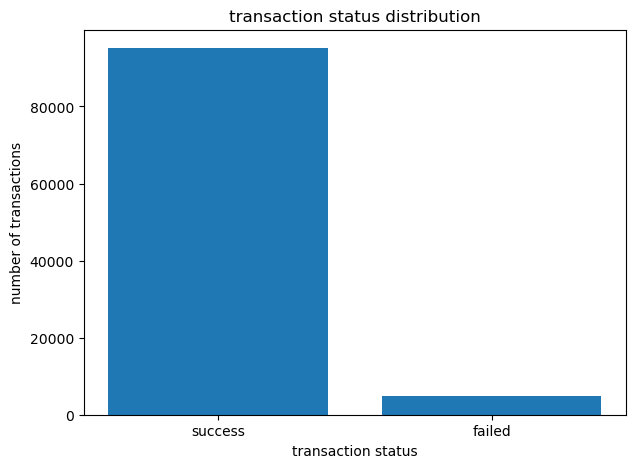

In [26]:
status_counts = df["transaction_status"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(status_counts.index, status_counts.values)

plt.title("transaction status distribution")
plt.xlabel("transaction status")
plt.ylabel("number of transactions")

plt.show()

In [27]:
#Failure reason data
failure_df = df[df["transaction_status"] == "failed"].copy()

failure_counts = (
    failure_df["failure_reason_id"]
    .value_counts()
    .sort_values(ascending=False)
)

failure_counts

failure_reason_id
5.0     445
9.0     445
2.0     444
12.0    411
6.0     411
10.0    410
3.0     405
11.0    399
7.0     381
1.0     374
8.0     366
4.0     361
Name: count, dtype: int64

In [28]:
failure_reason_columns = pd.read_sql("""
select
    column_name
from information_schema.columns
where table_name = 'failure_reasons'
order by ordinal_position;
""", conn)

failure_reason_columns

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\2227478902.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  failure_reason_columns = pd.read_sql("""


,column_name
0,failure_reason_id
1,failure_category
2,failure_reason


In [29]:
pd.read_sql("""
select *
from failure_reasons
limit 10;
""", conn)

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\3381558615.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql("""


,failure_reason_id,failure_category,failure_reason
0,1,technical failure,server error
1,2,technical failure,system unavailable
2,3,bank-side failure,bank server unavailable
3,4,bank-side failure,bank processing error
4,5,network failure,network timeout
5,6,network failure,poor network connectivity
6,7,timeout,transaction timed out
7,8,insufficient balance,insufficient account balance
8,9,invalid upi pin,incorrect upi pin
9,10,limit exceeded,daily transaction limit exceeded


In [30]:
failure_reasons = pd.read_sql("""
select
    failure_reason_id,
    failure_category,
    failure_reason
from failure_reasons;
""", conn)

failure_reasons

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\322978574.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  failure_reasons = pd.read_sql("""


,failure_reason_id,failure_category,failure_reason
0,1,technical failure,server error
1,2,technical failure,system unavailable
2,3,bank-side failure,bank server unavailable
3,4,bank-side failure,bank processing error
4,5,network failure,network timeout
5,6,network failure,poor network connectivity
6,7,timeout,transaction timed out
7,8,insufficient balance,insufficient account balance
8,9,invalid upi pin,incorrect upi pin
9,10,limit exceeded,daily transaction limit exceeded


In [31]:
df = df.merge(
    failure_reasons,
    on="failure_reason_id",
    how="left"
)

df.head()

,transaction_id,user_id,merchant_id,device_id,bank_id,location_id,transaction_date,transaction_amount,transaction_status,failure_reason_id,...,bank_type,merchant_name,merchant_category,city,state,region,urban_rural,device_type,failure_category,failure_reason
0,1,2222,310,519,12,19,2025-06-14 22:41:52.572596,31701.56,success,NaN,...,Private,Merchant_00310,E-commerce,Guwahati,Assam,North East,Urban,mobile,NaN,NaN
1,2,3991,1105,8157,9,3,2025-01-07 11:49:36.221277,25565.43,success,NaN,...,Private,Merchant_01105,Retail,Rishikesh,Uttarakhand,North,Urban,tablet,NaN,NaN
2,3,16,1597,8238,13,3,2025-06-07 04:59:32.594617,37309.19,success,NaN,...,Private,Merchant_01597,Fuel,Rishikesh,Uttarakhand,North,Urban,mobile,NaN,NaN
3,4,7934,124,5661,14,17,2025-10-27 15:27:12.347426,26659.71,success,NaN,...,Small Finance,Merchant_00124,Utilities,Bhubaneswar,Odisha,East,Urban,mobile,NaN,NaN
4,7,8162,477,10811,3,3,2025-04-26 19:51:33.652314,20582.12,success,NaN,...,Public,Merchant_00477,Government Services,Rishikesh,Uttarakhand,North,Urban,tablet,NaN,NaN


In [32]:
df[[
    "transaction_status",
    "failure_reason_id",
    "failure_category",
    "failure_reason"
]].head(10)

,transaction_status,failure_reason_id,failure_category,failure_reason
0,success,NaN,NaN,NaN
1,success,NaN,NaN,NaN
2,success,NaN,NaN,NaN
3,success,NaN,NaN,NaN
4,success,NaN,NaN,NaN
5,success,NaN,NaN,NaN
6,success,NaN,NaN,NaN
7,success,NaN,NaN,NaN
8,success,NaN,NaN,NaN
9,success,NaN,NaN,NaN


In [33]:
#failed transaction category


failure_category_counts = (
    df[df["transaction_status"] == "failed"]
    ["failure_category"]
    .value_counts()
)

failure_category_counts

failure_category
network failure         856
technical failure       818
risk verification       810
bank-side failure       766
invalid upi pin         445
limit exceeded          410
timeout                 381
insufficient balance    366
Name: count, dtype: int64

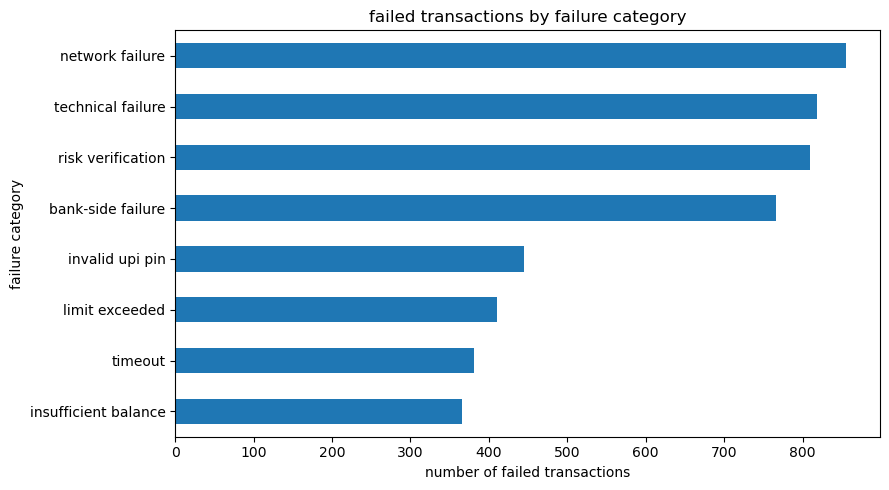

In [34]:
plt.figure(figsize=(9, 5))

failure_category_counts.sort_values().plot(
    kind="barh"
)

plt.title("failed transactions by failure category")
plt.xlabel("number of failed transactions")
plt.ylabel("failure category")

plt.tight_layout()
plt.show()

In [35]:
#detailed failure reason
failure_reason_counts = (
    df[df["transaction_status"] == "failed"]
    ["failure_reason"]
    .value_counts()
)

failure_reason_counts

failure_reason
network timeout                         445
incorrect upi pin                       445
system unavailable                      444
suspicious transaction detected         411
poor network connectivity               411
daily transaction limit exceeded        410
bank server unavailable                 405
transaction flagged for verification    399
transaction timed out                   381
server error                            374
insufficient account balance            366
bank processing error                   361
Name: count, dtype: int64

In [36]:
#Bank_wise transaction  performance 
bank_analysis = (
    df.groupby("bank_name")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

bank_analysis["failure_rate"] = (
    bank_analysis["failed_transactions"]
    / bank_analysis["total_transactions"]
    * 100
)

bank_analysis["success_rate"] = (
    bank_analysis["successful_transactions"]
    / bank_analysis["total_transactions"]
    * 100
)

bank_analysis = bank_analysis.sort_values(
    "failure_rate",
    ascending=False
)

bank_analysis

,bank_name,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
8,IndusInd Bank,6745,356,6389,1.693448e+08,5.277984,94.722016
11,State Bank of India,6606,342,6264,1.676504e+08,5.177112,94.822888
12,Ujjivan Small Finance Bank,6658,344,6314,1.648837e+08,5.166717,94.833283
3,Canara Bank,6686,341,6345,1.647071e+08,5.100209,94.899791
14,Yes Bank,6808,341,6467,1.713905e+08,5.008813,94.991187
0,AU Small Finance Bank,6641,330,6311,1.667484e+08,4.969131,95.030869
13,Union Bank of India,6610,324,6286,1.647725e+08,4.901664,95.098336
9,Kotak Mahindra Bank,6733,329,6404,1.689817e+08,4.886381,95.113619
6,ICICI Bank,6738,329,6409,1.702014e+08,4.882755,95.117245
1,Axis Bank,6600,312,6288,1.658405e+08,4.727273,95.272727


In [37]:
bank_analysis["failure_rate"] = bank_analysis["failure_rate"].round(2)
bank_analysis["success_rate"] = bank_analysis["success_rate"].round(2)

bank_analysis

,bank_name,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
8,IndusInd Bank,6745,356,6389,1.693448e+08,5.28,94.72
11,State Bank of India,6606,342,6264,1.676504e+08,5.18,94.82
12,Ujjivan Small Finance Bank,6658,344,6314,1.648837e+08,5.17,94.83
3,Canara Bank,6686,341,6345,1.647071e+08,5.10,94.90
14,Yes Bank,6808,341,6467,1.713905e+08,5.01,94.99
0,AU Small Finance Bank,6641,330,6311,1.667484e+08,4.97,95.03
13,Union Bank of India,6610,324,6286,1.647725e+08,4.90,95.10
9,Kotak Mahindra Bank,6733,329,6404,1.689817e+08,4.89,95.11
6,ICICI Bank,6738,329,6409,1.702014e+08,4.88,95.12
1,Axis Bank,6600,312,6288,1.658405e+08,4.73,95.27


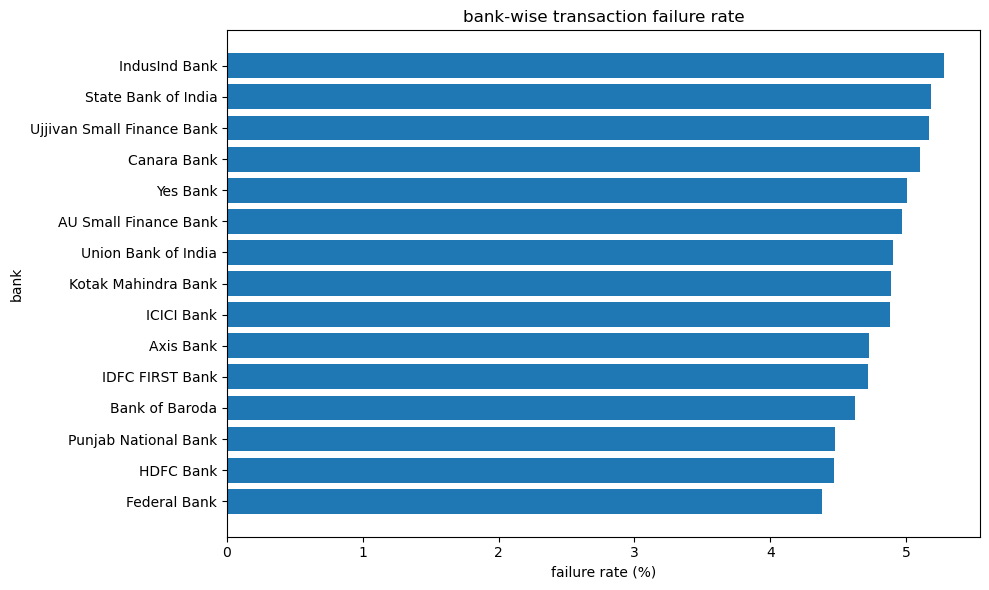

In [38]:
#Bank failure rate chart
plt.figure(figsize=(10, 6))

plt.barh(
    bank_analysis["bank_name"],
    bank_analysis["failure_rate"]
)

plt.xlabel("failure rate (%)")
plt.ylabel("bank")
plt.title("bank-wise transaction failure rate")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [39]:
#transaction volume
bank_analysis.sort_values(
    "total_transactions",
    ascending=False
)[[
    "bank_name",
    "total_transactions",
    "failed_transactions",
    "failure_rate"
]]

,bank_name,total_transactions,failed_transactions,failure_rate
14,Yes Bank,6808,341,5.01
8,IndusInd Bank,6745,356,5.28
6,ICICI Bank,6738,329,4.88
9,Kotak Mahindra Bank,6733,329,4.89
4,Federal Bank,6697,293,4.38
3,Canara Bank,6686,341,5.10
12,Ujjivan Small Finance Bank,6658,344,5.17
7,IDFC FIRST Bank,6653,314,4.72
5,HDFC Bank,6644,297,4.47
0,AU Small Finance Bank,6641,330,4.97


In [40]:
#city wise performance
city_analysis = (
    df.groupby("city")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

city_analysis["failure_rate"] = (
    city_analysis["failed_transactions"]
    / city_analysis["total_transactions"]
    * 100
)

city_analysis["success_rate"] = (
    city_analysis["successful_transactions"]
    / city_analysis["total_transactions"]
    * 100
)

city_analysis["failure_rate"] = city_analysis["failure_rate"].round(2)
city_analysis["success_rate"] = city_analysis["success_rate"].round(2)

city_analysis

,city,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
0,Ahmedabad,5071,236,4835,1.259567e+08,4.65,95.35
1,Bengaluru,4962,227,4735,1.263082e+08,4.57,95.43
2,Bhopal,5044,241,4803,1.267703e+08,4.78,95.22
3,Bhubaneswar,4957,254,4703,1.223783e+08,5.12,94.88
4,Chandigarh,4932,234,4698,1.236949e+08,4.74,95.26
5,Chennai,4906,226,4680,1.230221e+08,4.61,95.39
6,Dehradun,5059,229,4830,1.269064e+08,4.53,95.47
7,Delhi,4949,253,4696,1.253308e+08,5.11,94.89
8,Guwahati,4982,258,4724,1.239142e+08,5.18,94.82
9,Haridwar,4940,208,4732,1.244799e+08,4.21,95.79


In [41]:
#Highest failure-rate cities

top_failure_cities = (
    city_analysis
    .sort_values("failure_rate", ascending=False)
    .head(10)
)

top_failure_cities

,city,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
19,Surat,4987,276,4711,1.257680e+08,5.53,94.47
13,Kolkata,5013,272,4741,1.263180e+08,5.43,94.57
16,Patna,5069,270,4799,1.262946e+08,5.33,94.67
8,Guwahati,4982,258,4724,1.239142e+08,5.18,94.82
3,Bhubaneswar,4957,254,4703,1.223783e+08,5.12,94.88
7,Delhi,4949,253,4696,1.253308e+08,5.11,94.89
17,Pune,4929,247,4682,1.245321e+08,5.01,94.99
15,Mumbai,5134,256,4878,1.291853e+08,4.99,95.01
10,Hyderabad,5076,253,4823,1.266847e+08,4.98,95.02
2,Bhopal,5044,241,4803,1.267703e+08,4.78,95.22


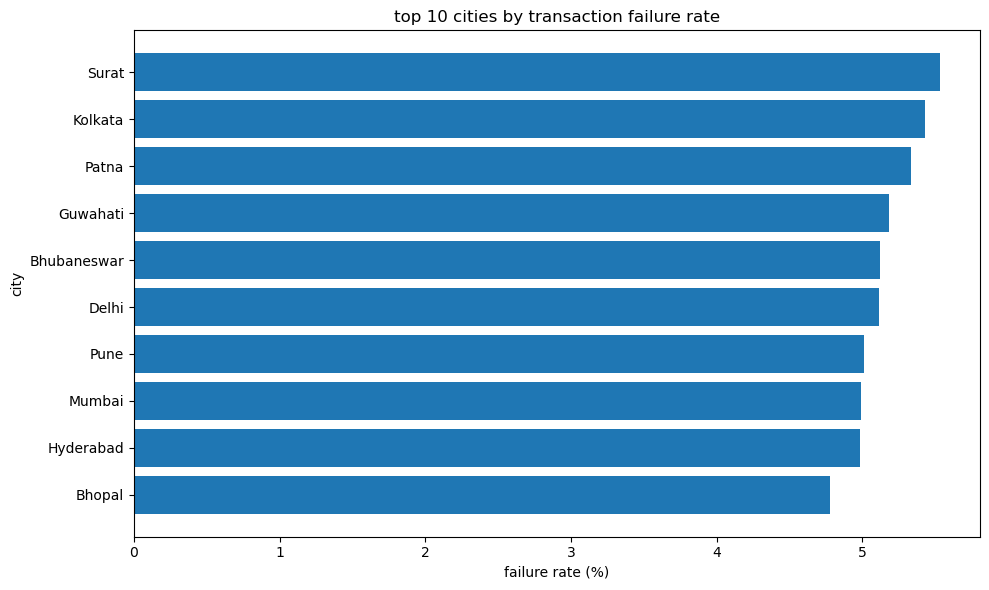

In [42]:
#top 10 city
plt.figure(figsize=(10, 6))

plt.barh(
    top_failure_cities["city"],
    top_failure_cities["failure_rate"]
)

plt.xlabel("failure rate (%)")
plt.ylabel("city")
plt.title("top 10 cities by transaction failure rate")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [43]:
top_failure_cities[[
    "city",
    "total_transactions",
    "failed_transactions",
    "failure_rate"
]]

,city,total_transactions,failed_transactions,failure_rate
19,Surat,4987,276,5.53
13,Kolkata,5013,272,5.43
16,Patna,5069,270,5.33
8,Guwahati,4982,258,5.18
3,Bhubaneswar,4957,254,5.12
7,Delhi,4949,253,5.11
17,Pune,4929,247,5.01
15,Mumbai,5134,256,4.99
10,Hyderabad,5076,253,4.98
2,Bhopal,5044,241,4.78


In [44]:
#state wise failure rate
state_analysis = (
    df.groupby("state")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum())
    )
    .reset_index()
)

state_analysis["failure_rate"] = (
    state_analysis["failed_transactions"]
    / state_analysis["total_transactions"]
    * 100
).round(2)

state_analysis = state_analysis.sort_values(
    "failure_rate",
    ascending=False
)

state_analysis

,state,total_transactions,failed_transactions,failure_rate
15,West Bengal,5013,272,5.43
1,Bihar,5069,270,5.33
0,Assam,4982,258,5.18
9,Odisha,4957,254,5.12
3,Delhi,4949,253,5.11
4,Gujarat,10058,512,5.09
8,Maharashtra,10063,503,5.00
12,Telangana,5076,253,4.98
7,Madhya Pradesh,5044,241,4.78
10,Rajasthan,4997,237,4.74


In [45]:
# create hour column
df["hour"] = df["transaction_date"].dt.hour

df[["transaction_date", "hour"]].head()

,transaction_date,hour
0,2025-06-14 22:41:52.572596,22
1,2025-01-07 11:49:36.221277,11
2,2025-06-07 04:59:32.594617,4
3,2025-10-27 15:27:12.347426,15
4,2025-04-26 19:51:33.652314,19


In [46]:
df["hour"].min(), df["hour"].max()

(0, 23)

In [47]:
#hourly transaction
hourly_analysis = (
    df.groupby("hour")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum())
    )
    .reset_index()
)

hourly_analysis

,hour,total_transactions,failed_transactions
0,0,4273,194
1,1,4212,235
2,2,4119,203
3,3,4140,184
4,4,4071,178
5,5,4254,225
6,6,4237,194
7,7,4073,195
8,8,4044,183
9,9,4240,194


In [48]:
#hourly failure rate
hourly_analysis["failure_rate"] = (
    hourly_analysis["failed_transactions"]
    / hourly_analysis["total_transactions"]
    * 100
).round(2)

hourly_analysis

,hour,total_transactions,failed_transactions,failure_rate
0,0,4273,194,4.54
1,1,4212,235,5.58
2,2,4119,203,4.93
3,3,4140,184,4.44
4,4,4071,178,4.37
5,5,4254,225,5.29
6,6,4237,194,4.58
7,7,4073,195,4.79
8,8,4044,183,4.53
9,9,4240,194,4.58


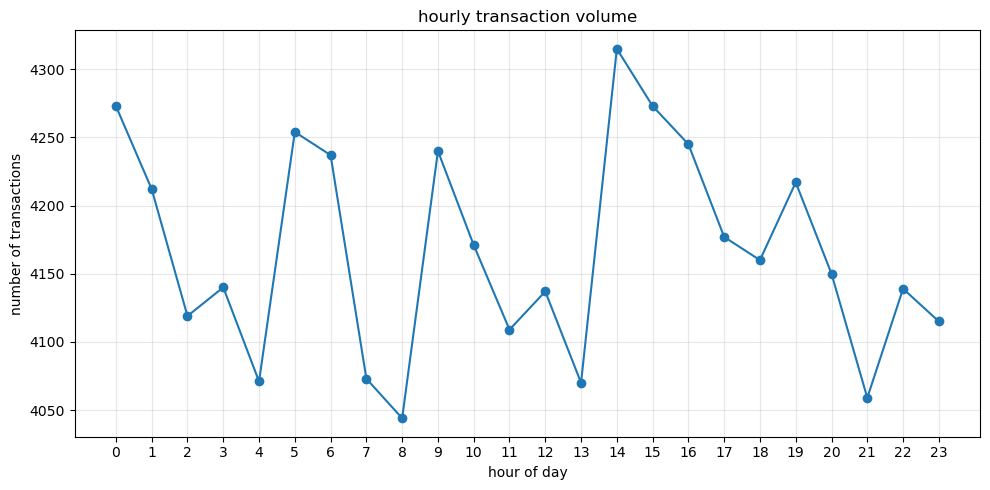

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_analysis["hour"],
    hourly_analysis["total_transactions"],
    marker="o"
)

plt.title("hourly transaction volume")
plt.xlabel("hour of day")
plt.ylabel("number of transactions")

plt.xticks(range(24))

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

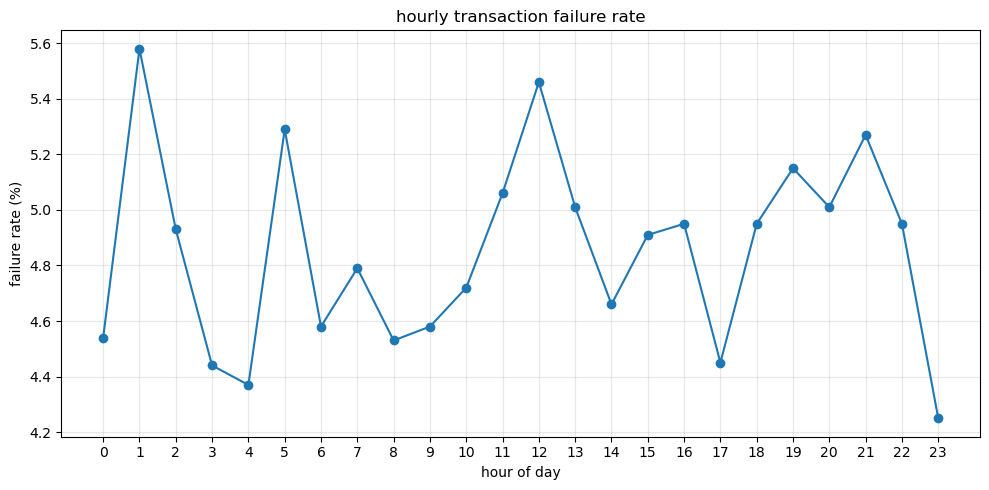

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_analysis["hour"],
    hourly_analysis["failure_rate"],
    marker="o"
)

plt.title("hourly transaction failure rate")
plt.xlabel("hour of day")
plt.ylabel("failure rate (%)")

plt.xticks(range(24))

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
#highest failure hrs
hourly_analysis.sort_values(
    "failure_rate",
    ascending=False
).head(5)

,hour,total_transactions,failed_transactions,failure_rate
1,1,4212,235,5.58
12,12,4137,226,5.46
5,5,4254,225,5.29
21,21,4059,214,5.27
19,19,4217,217,5.15


In [52]:
hourly_analysis.sort_values(
    "total_transactions",
    ascending=False
).head(5)

,hour,total_transactions,failed_transactions,failure_rate
14,14,4315,201,4.66
0,0,4273,194,4.54
15,15,4273,210,4.91
5,5,4254,225,5.29
16,16,4245,210,4.95


In [53]:
#create month
df["month"] = df["transaction_date"].dt.to_period("M").astype(str)

df[["transaction_date", "month"]].head()

,transaction_date,month
0,2025-06-14 22:41:52.572596,2025-06
1,2025-01-07 11:49:36.221277,2025-01
2,2025-06-07 04:59:32.594617,2025-06
3,2025-10-27 15:27:12.347426,2025-10
4,2025-04-26 19:51:33.652314,2025-04


In [54]:
df["month"].unique()


array(['2025-06', '2025-01', '2025-10', '2025-04', '2025-03', '2025-12',
       '2025-08', '2025-05', '2025-07', '2025-02', '2025-11', '2025-09'],
      dtype=object)

In [55]:
#monthly performance
monthly_analysis = (
    df.groupby("month")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

monthly_analysis["failure_rate"] = (
    monthly_analysis["failed_transactions"]
    / monthly_analysis["total_transactions"]
    * 100
).round(2)

monthly_analysis["success_rate"] = (
    monthly_analysis["successful_transactions"]
    / monthly_analysis["total_transactions"]
    * 100
).round(2)

monthly_analysis

,month,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate,success_rate
0,2025-01,8429,8011,418,2.117410e+08,4.96,95.04
1,2025-02,7721,7322,399,1.926141e+08,5.17,94.83
2,2025-03,8499,8083,416,2.124189e+08,4.89,95.11
3,2025-04,8148,7718,430,2.055008e+08,5.28,94.72
4,2025-05,8409,8029,380,2.112647e+08,4.52,95.48
5,2025-06,8266,7882,384,2.066914e+08,4.65,95.35
6,2025-07,8526,8107,419,2.141671e+08,4.91,95.09
7,2025-08,8547,8134,413,2.162792e+08,4.83,95.17
8,2025-09,8163,7758,405,2.057135e+08,4.96,95.04
9,2025-10,8543,8151,392,2.140252e+08,4.59,95.41


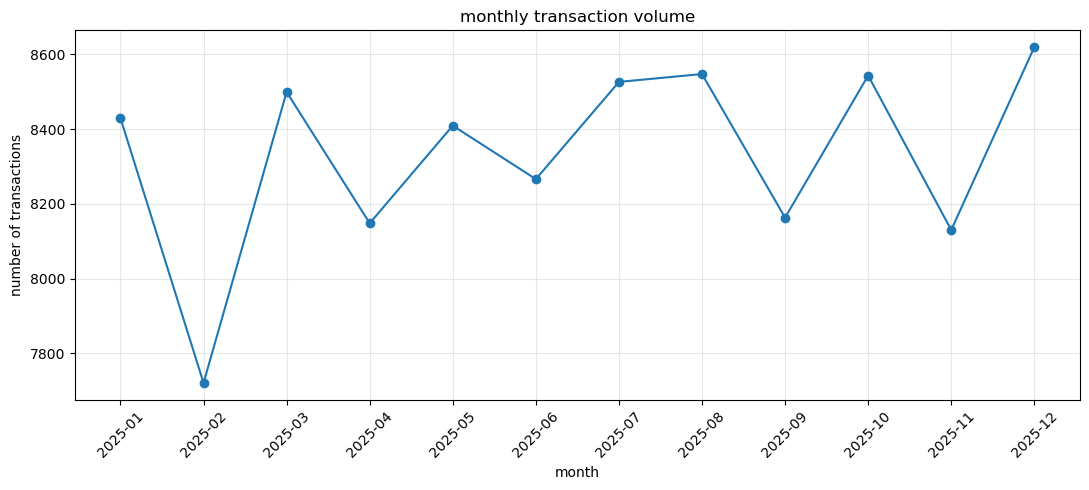

In [56]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_analysis["month"],
    monthly_analysis["total_transactions"],
    marker="o"
)

plt.title("monthly transaction volume")
plt.xlabel("month")
plt.ylabel("number of transactions")

plt.xticks(rotation=45)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

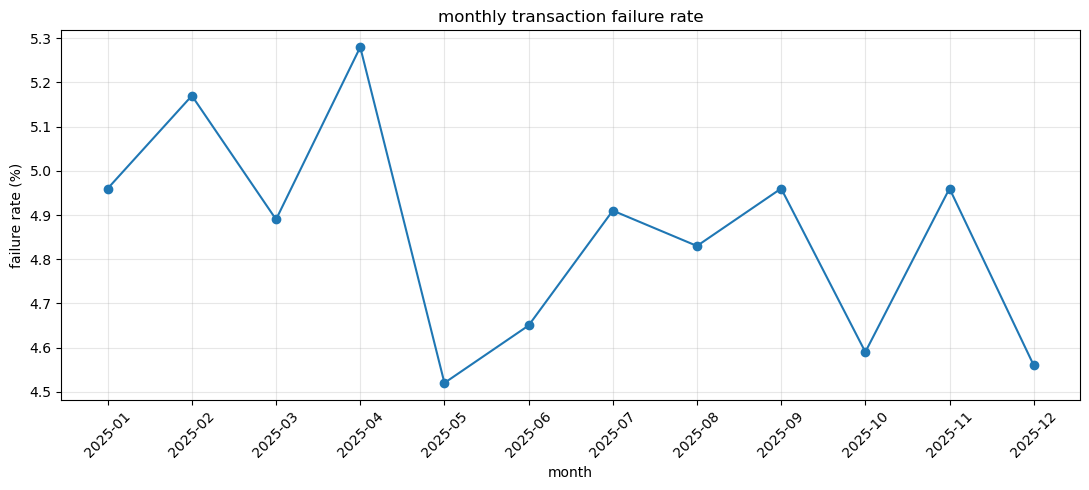

In [57]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_analysis["month"],
    monthly_analysis["failure_rate"],
    marker="o"
)

plt.title("monthly transaction failure rate")
plt.xlabel("month")
plt.ylabel("failure rate (%)")

plt.xticks(rotation=45)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

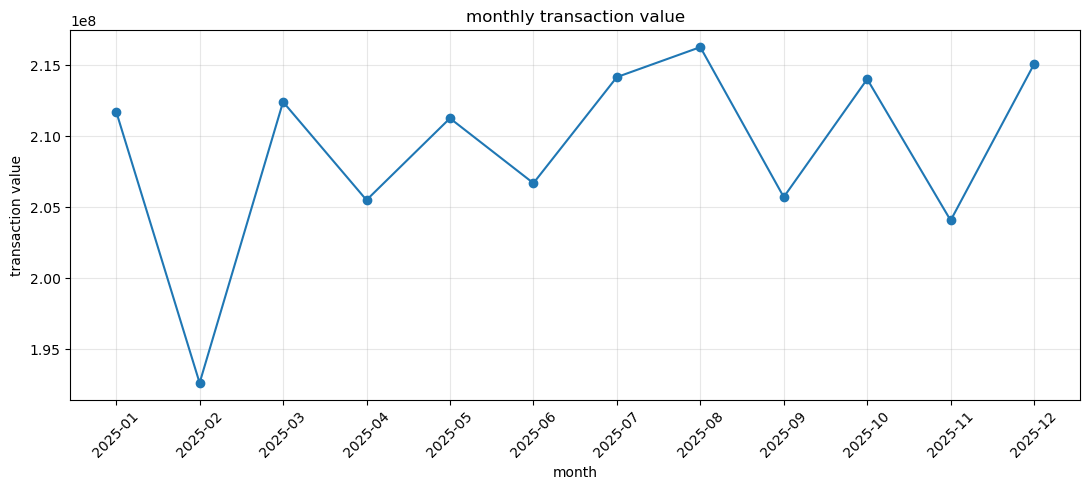

In [58]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_analysis["month"],
    monthly_analysis["total_transaction_value"],
    marker="o"
)

plt.title("monthly transaction value")
plt.xlabel("month")
plt.ylabel("transaction value")

plt.xticks(rotation=45)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [59]:
#highest failure mnth
monthly_analysis.sort_values(
    "failure_rate",
    ascending=False
).head(5)

,month,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate,success_rate
3,2025-04,8148,7718,430,2.055008e+08,5.28,94.72
1,2025-02,7721,7322,399,1.926141e+08,5.17,94.83
0,2025-01,8429,8011,418,2.117410e+08,4.96,95.04
10,2025-11,8130,7727,403,2.040681e+08,4.96,95.04
8,2025-09,8163,7758,405,2.057135e+08,4.96,95.04


In [60]:
#highest transaction-volumne mnth
monthly_analysis.sort_values(
    "total_transactions",
    ascending=False
).head(5)

,month,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate,success_rate
11,2025-12,8619,8226,393,2.150842e+08,4.56,95.44
7,2025-08,8547,8134,413,2.162792e+08,4.83,95.17
9,2025-10,8543,8151,392,2.140252e+08,4.59,95.41
6,2025-07,8526,8107,419,2.141671e+08,4.91,95.09
2,2025-03,8499,8083,416,2.124189e+08,4.89,95.11


In [61]:
#retry vs nor retry trans
retry_analysis = (
    df.groupby("is_retry")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

retry_analysis

,is_retry,total_transactions,successful_transactions,failed_transactions,total_transaction_value
0,False,90000,88024,1976,2.261347e+09
1,True,10000,7124,2876,2.482216e+08


In [62]:
#success & failure rate
retry_analysis["success_rate"] = (
    retry_analysis["successful_transactions"]
    / retry_analysis["total_transactions"]
    * 100
).round(2)

retry_analysis["failure_rate"] = (
    retry_analysis["failed_transactions"]
    / retry_analysis["total_transactions"]
    * 100
).round(2)

retry_analysis

,is_retry,total_transactions,successful_transactions,failed_transactions,total_transaction_value,success_rate,failure_rate
0,False,90000,88024,1976,2.261347e+09,97.80,2.20
1,True,10000,7124,2876,2.482216e+08,71.24,28.76


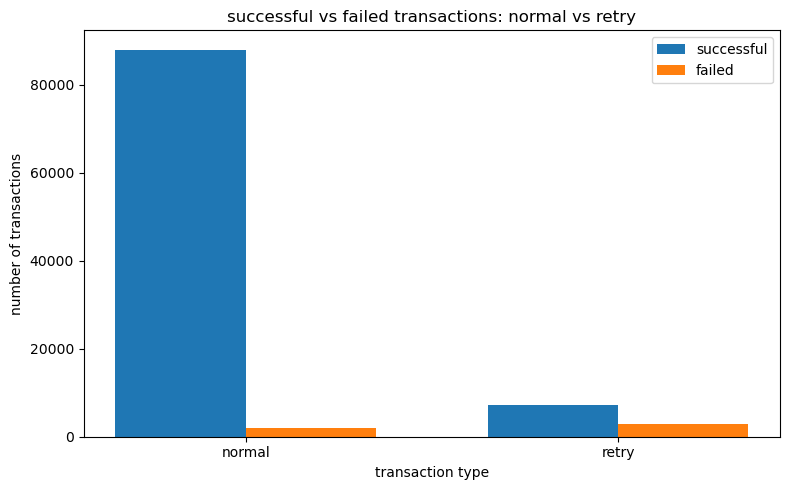

In [63]:
#retry vs non retry comparision
plot_data = retry_analysis.copy()

plot_data["transaction_type"] = plot_data["is_retry"].map({
    False: "normal",
    True: "retry"
})

x = np.arange(len(plot_data))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    plot_data["successful_transactions"],
    width,
    label="successful"
)

plt.bar(
    x + width / 2,
    plot_data["failed_transactions"],
    width,
    label="failed"
)

plt.xticks(x, plot_data["transaction_type"])

plt.xlabel("transaction type")
plt.ylabel("number of transactions")
plt.title("successful vs failed transactions: normal vs retry")

plt.legend()

plt.tight_layout()
plt.show()

In [64]:
#retry success rate
retry_only = df[df["is_retry"] == True]

retry_success_rate = (
    (retry_only["transaction_status"] == "success").sum()
    / len(retry_only)
    * 100
)

print("retry success rate:", round(retry_success_rate, 2), "%")

retry success rate: 71.24 %


In [65]:
#retry failure reason
retry_failure_reasons = (
    retry_only[retry_only["transaction_status"] == "failed"]
    ["failure_category"]
    .value_counts()
)

retry_failure_reasons

failure_category
network failure         514
technical failure       499
risk verification       471
bank-side failure       452
invalid upi pin         267
limit exceeded          233
timeout                 229
insufficient balance    211
Name: count, dtype: int64

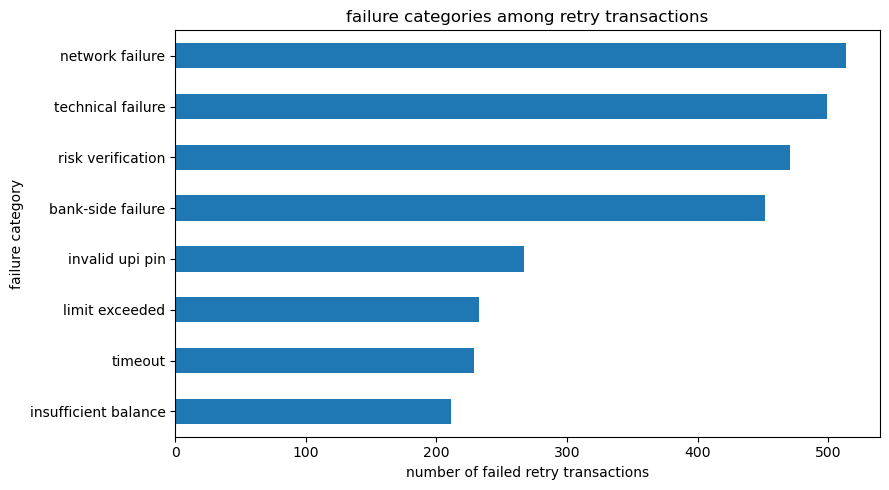

In [66]:
plt.figure(figsize=(9, 5))

retry_failure_reasons.sort_values().plot(
    kind="barh"
)

plt.xlabel("number of failed retry transactions")
plt.ylabel("failure category")
plt.title("failure categories among retry transactions")

plt.tight_layout()
plt.show()

In [67]:
#channel wise analysis
channel_analysis = (
    df.groupby("payment_channel")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

channel_analysis["failure_rate"] = (
    channel_analysis["failed_transactions"]
    / channel_analysis["total_transactions"]
    * 100
).round(2)

channel_analysis["success_rate"] = (
    channel_analysis["successful_transactions"]
    / channel_analysis["total_transactions"]
    * 100
).round(2)

channel_analysis

,payment_channel,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
0,collect_request,25057,1250,23807,6.267211e+08,4.99,95.01
1,qr,25067,1223,23844,6.295555e+08,4.88,95.12
2,upi_app,24819,1202,23617,6.239551e+08,4.84,95.16
3,upi_id,25057,1177,23880,6.293365e+08,4.70,95.30


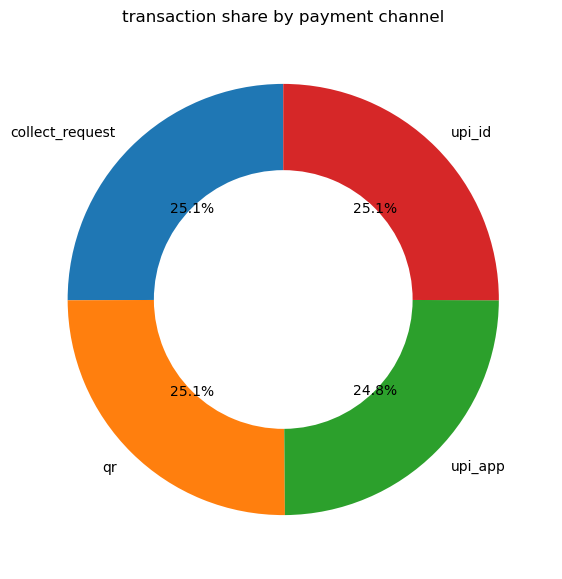

In [68]:
#trans share
plt.figure(figsize=(7, 7))

plt.pie(
    channel_analysis["total_transactions"],
    labels=channel_analysis["payment_channel"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.4)
)

plt.title("transaction share by payment channel")
plt.show()

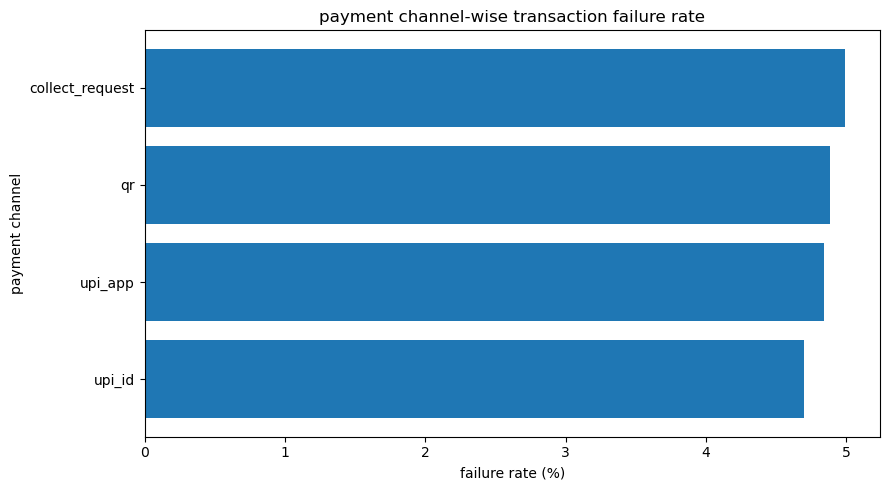

In [69]:
#failure rate
channel_analysis = channel_analysis.sort_values(
    "failure_rate",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    channel_analysis["payment_channel"],
    channel_analysis["failure_rate"]
)

plt.xlabel("failure rate (%)")
plt.ylabel("payment channel")
plt.title("payment channel-wise transaction failure rate")

plt.tight_layout()
plt.show()

In [70]:
channel_analysis.sort_values(
    "failure_rate",
    ascending=False
)[[
    "payment_channel",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "success_rate",
    "failure_rate"
]]

,payment_channel,total_transactions,successful_transactions,failed_transactions,success_rate,failure_rate
0,collect_request,25057,23807,1250,95.01,4.99
1,qr,25067,23844,1223,95.12,4.88
2,upi_app,24819,23617,1202,95.16,4.84
3,upi_id,25057,23880,1177,95.30,4.70


In [71]:
#device wise analysis
device_analysis = (
    df.groupby("device_type")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

device_analysis["success_rate"] = (
    device_analysis["successful_transactions"]
    / device_analysis["total_transactions"]
    * 100
).round(2)

device_analysis["failure_rate"] = (
    device_analysis["failed_transactions"]
    / device_analysis["total_transactions"]
    * 100
).round(2)

device_analysis

,device_type,total_transactions,successful_transactions,failed_transactions,total_transaction_value,success_rate,failure_rate
0,mobile,69742,66298,3444,1.750740e+09,95.06,4.94
1,other,3063,2918,145,7.587136e+07,95.27,4.73
2,tablet,27195,25932,1263,6.829568e+08,95.36,4.64


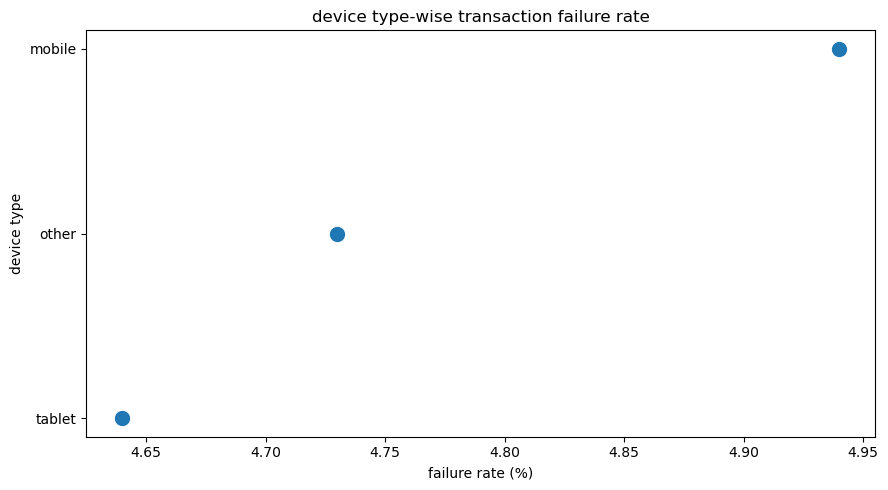

In [72]:
#device failure rate
device_analysis = device_analysis.sort_values(
    "failure_rate",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.scatter(
    device_analysis["failure_rate"],
    device_analysis["device_type"],
    s=100
)

plt.xlabel("failure rate (%)")
plt.ylabel("device type")
plt.title("device type-wise transaction failure rate")

plt.tight_layout()
plt.show()

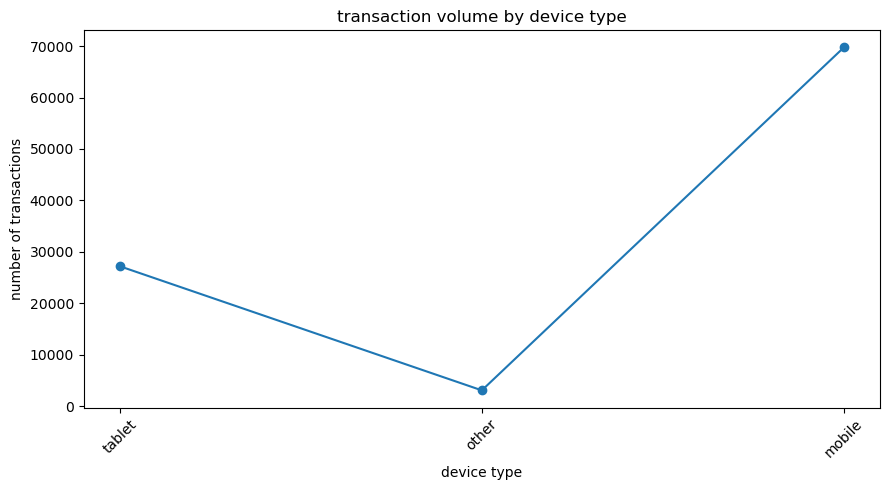

In [73]:
#device tran volume
plt.figure(figsize=(9, 5))

plt.plot(
    device_analysis["device_type"],
    device_analysis["total_transactions"],
    marker="o"
)

plt.xlabel("device type")
plt.ylabel("number of transactions")
plt.title("transaction volume by device type")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [74]:
device_analysis.sort_values(
    "failure_rate",
    ascending=False
)[[
    "device_type",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "success_rate",
    "failure_rate"
]]

,device_type,total_transactions,successful_transactions,failed_transactions,success_rate,failure_rate
0,mobile,69742,66298,3444,95.06,4.94
1,other,3063,2918,145,95.27,4.73
2,tablet,27195,25932,1263,95.36,4.64


In [75]:
#age grup analysis
age_group_analysis = (
    df.groupby("age_group")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

age_group_analysis["success_rate"] = (
    age_group_analysis["successful_transactions"]
    / age_group_analysis["total_transactions"]
    * 100
).round(2)

age_group_analysis["failure_rate"] = (
    age_group_analysis["failed_transactions"]
    / age_group_analysis["total_transactions"]
    * 100
).round(2)

age_group_analysis

,age_group,total_transactions,successful_transactions,failed_transactions,total_transaction_value,success_rate,failure_rate
0,18-24,9567,9100,467,2.395036e+08,95.12,4.88
1,25-34,26559,25236,1323,6.650823e+08,95.02,4.98
2,35-44,35149,33450,1699,8.850955e+08,95.17,4.83
3,45-54,23233,22125,1108,5.834073e+08,95.23,4.77
4,55-64,5110,4876,234,1.273873e+08,95.42,4.58
5,65+,382,361,21,9.092376e+06,94.50,5.50


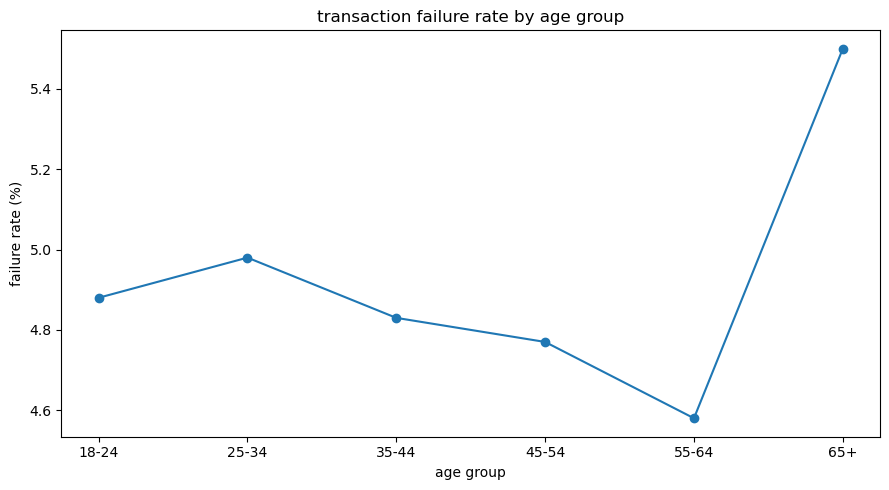

In [76]:
#failure rate
plt.figure(figsize=(9, 5))

plt.plot(
    age_group_analysis["age_group"],
    age_group_analysis["failure_rate"],
    marker="o"
)

plt.xlabel("age group")
plt.ylabel("failure rate (%)")
plt.title("transaction failure rate by age group")

plt.tight_layout()
plt.show()

In [77]:
age_group_analysis.sort_values(
    "failure_rate",
    ascending=False
)[[
    "age_group",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "success_rate",
    "failure_rate",
    "total_transaction_value"
]]

,age_group,total_transactions,successful_transactions,failed_transactions,success_rate,failure_rate,total_transaction_value
5,65+,382,361,21,94.50,5.50,9.092376e+06
1,25-34,26559,25236,1323,95.02,4.98,6.650823e+08
0,18-24,9567,9100,467,95.12,4.88,2.395036e+08
2,35-44,35149,33450,1699,95.17,4.83,8.850955e+08
3,45-54,23233,22125,1108,95.23,4.77,5.834073e+08
4,55-64,5110,4876,234,95.42,4.58,1.273873e+08


<Figure size 900x500 with 0 Axes>

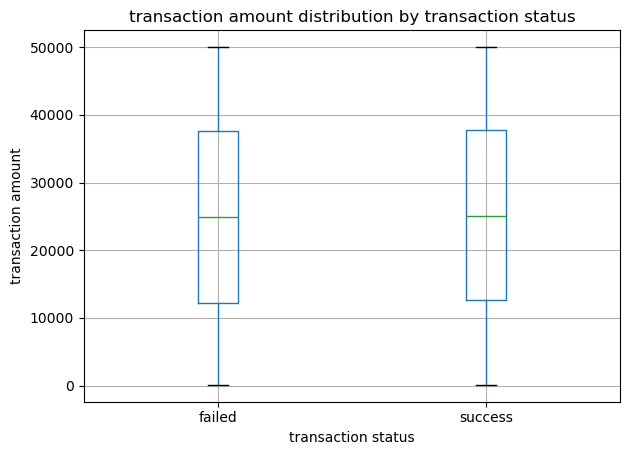

In [78]:
#Success vs failure amount distribution
plt.figure(figsize=(9, 5))

df.boxplot(
    column="transaction_amount",
    by="transaction_status"
)

plt.title("transaction amount distribution by transaction status")
plt.suptitle("")
plt.xlabel("transaction status")
plt.ylabel("transaction amount")

plt.tight_layout()
plt.show()

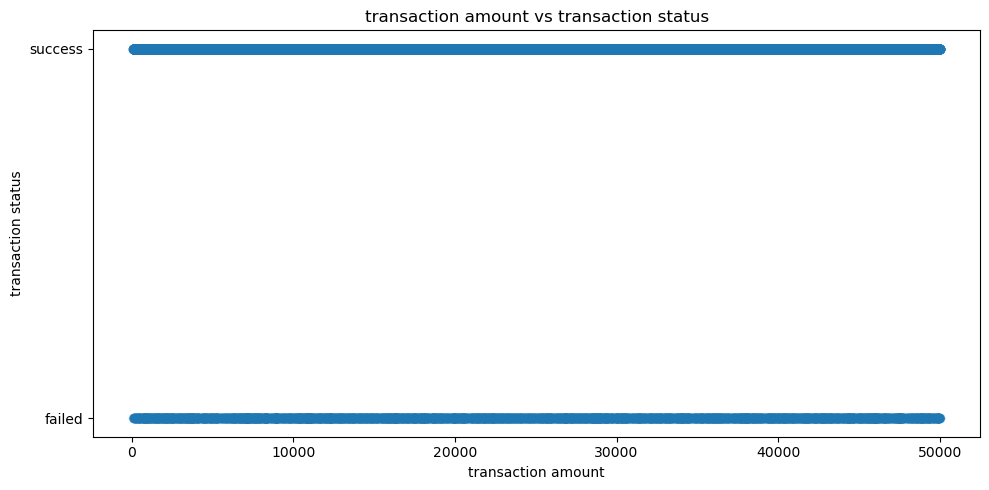

In [79]:
#Amount vs transaction status
status_map = {
    "success": 1,
    "failed": 0
}

plt.figure(figsize=(10, 5))

plt.scatter(
    df["transaction_amount"],
    df["transaction_status"].map(status_map),
    alpha=0.3
)

plt.yticks(
    [0, 1],
    ["failed", "success"]
)

plt.xlabel("transaction amount")
plt.ylabel("transaction status")
plt.title("transaction amount vs transaction status")

plt.tight_layout()
plt.show()

In [80]:
#amount range
df["amount_range"] = pd.cut(
    df["transaction_amount"],
    bins=[0, 500, 1000, 5000, 10000, float("inf")],
    labels=[
        "0-500",
        "501-1000",
        "1001-5000",
        "5001-10000",
        "10000+"
    ]
)

In [81]:
#Amount range-wise failure rate
amount_analysis = (
    df.groupby("amount_range", observed=False)
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum())
    )
    .reset_index()
)

amount_analysis["failure_rate"] = (
    amount_analysis["failed_transactions"]
    / amount_analysis["total_transactions"]
    * 100
).round(2)

amount_analysis["success_rate"] = (
    amount_analysis["successful_transactions"]
    / amount_analysis["total_transactions"]
    * 100
).round(2)

amount_analysis

,amount_range,total_transactions,failed_transactions,successful_transactions,failure_rate,success_rate
0,0-500,787,38,749,4.83,95.17
1,501-1000,1004,52,952,5.18,94.82
2,1001-5000,8045,407,7638,5.06,94.94
3,5001-10000,10001,485,9516,4.85,95.15
4,10000+,80163,3870,76293,4.83,95.17


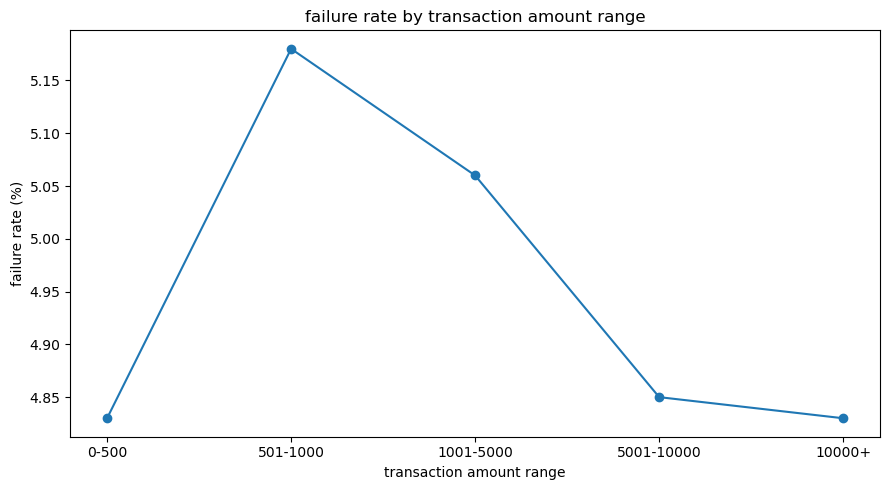

In [82]:
#Failure rate by amount range
plt.figure(figsize=(9, 5))

plt.plot(
    amount_analysis["amount_range"].astype(str),
    amount_analysis["failure_rate"],
    marker="o"
)

plt.xlabel("transaction amount range")
plt.ylabel("failure rate (%)")
plt.title("failure rate by transaction amount range")

plt.tight_layout()
plt.show()

In [83]:
#Merchant category analysis
merchant_analysis = (
    df.groupby("merchant_category")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

merchant_analysis["failure_rate"] = (
    merchant_analysis["failed_transactions"]
    / merchant_analysis["total_transactions"]
    * 100
).round(2)

merchant_analysis["success_rate"] = (
    merchant_analysis["successful_transactions"]
    / merchant_analysis["total_transactions"]
    * 100
).round(2)

merchant_analysis

,merchant_category,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate,success_rate
0,E-commerce,11234,10697,537,2.807238e+08,4.78,95.22
1,Education,10645,10138,507,2.635233e+08,4.76,95.24
2,Fuel,10961,10468,493,2.739896e+08,4.50,95.50
3,Government Services,9146,8695,451,2.293871e+08,4.93,95.07
4,Grocery,10506,9971,535,2.665830e+08,5.09,94.91
5,Pharmacy,8388,7960,428,2.102435e+08,5.10,94.90
6,Restaurant,10490,9952,538,2.635657e+08,5.13,94.87
7,Retail,9571,9093,478,2.400955e+08,4.99,95.01
8,Travel,9008,8591,417,2.277928e+08,4.63,95.37
9,Utilities,10051,9583,468,2.536639e+08,4.66,95.34


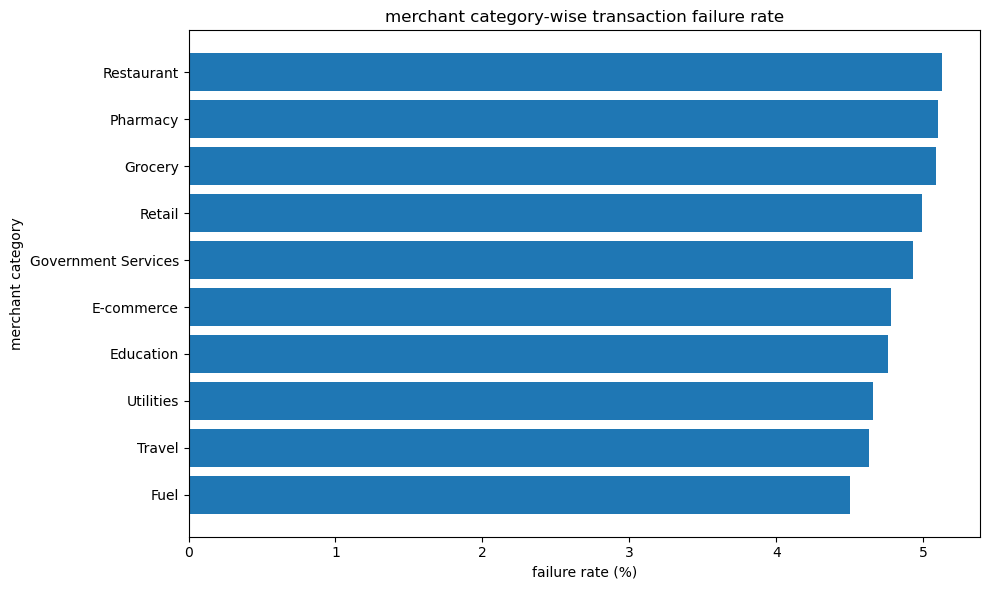

In [84]:
#Failure rate visualization
merchant_analysis = merchant_analysis.sort_values(
    "failure_rate",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    merchant_analysis["merchant_category"],
    merchant_analysis["failure_rate"]
)

plt.xlabel("failure rate (%)")
plt.ylabel("merchant category")
plt.title("merchant category-wise transaction failure rate")

plt.tight_layout()
plt.show()

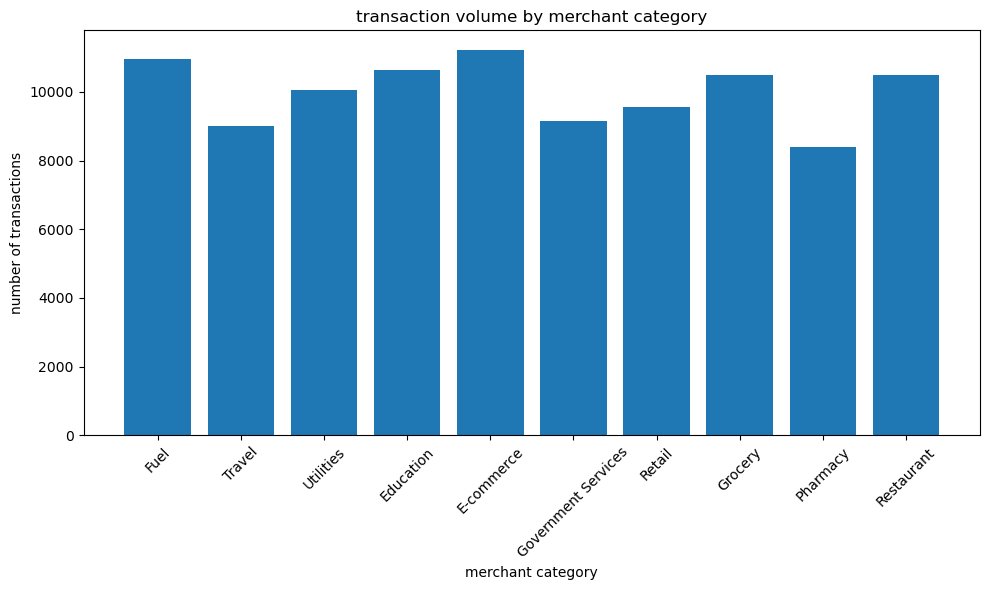

In [85]:
plt.figure(figsize=(10, 6))

plt.bar(
    merchant_analysis["merchant_category"],
    merchant_analysis["total_transactions"]
)

plt.xlabel("merchant category")
plt.ylabel("number of transactions")
plt.title("transaction volume by merchant category")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [86]:
merchant_analysis.sort_values(
    "failure_rate",
    ascending=False
)[[
    "merchant_category",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "success_rate",
    "failure_rate",
    "total_transaction_value"
]]

,merchant_category,total_transactions,successful_transactions,failed_transactions,success_rate,failure_rate,total_transaction_value
6,Restaurant,10490,9952,538,94.87,5.13,2.635657e+08
5,Pharmacy,8388,7960,428,94.90,5.10,2.102435e+08
4,Grocery,10506,9971,535,94.91,5.09,2.665830e+08
7,Retail,9571,9093,478,95.01,4.99,2.400955e+08
3,Government Services,9146,8695,451,95.07,4.93,2.293871e+08
0,E-commerce,11234,10697,537,95.22,4.78,2.807238e+08
1,Education,10645,10138,507,95.24,4.76,2.635233e+08
9,Utilities,10051,9583,468,95.34,4.66,2.536639e+08
8,Travel,9008,8591,417,95.37,4.63,2.277928e+08
2,Fuel,10961,10468,493,95.50,4.50,2.739896e+08


In [87]:
device_columns = pd.read_sql("""
select
    column_name,
    data_type
from information_schema.columns
where table_name = 'devices'
order by ordinal_position;
""", conn)

device_columns

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\3430084404.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  device_columns = pd.read_sql("""


,column_name,data_type
0,device_id,integer
1,user_id,integer
2,device_type,character varying
3,operating_system,character varying
4,network_type,character varying


In [88]:
network_data = pd.read_sql("""
select
    device_id,
    network_type
from devices;
""", conn)

df = df.drop(columns=["network_type"], errors="ignore")

df = df.merge(
    network_data,
    on="device_id",
    how="left"
)

df[["device_id", "network_type"]].head()

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\4032217307.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  network_data = pd.read_sql("""


,device_id,network_type
0,519,5g
1,8157,4g
2,8238,4g
3,5661,4g
4,10811,4g


In [89]:
network_analysis = (
    df.groupby("network_type")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

network_analysis["success_rate"] = (
    network_analysis["successful_transactions"]
    / network_analysis["total_transactions"]
    * 100
).round(2)

network_analysis["failure_rate"] = (
    network_analysis["failed_transactions"]
    / network_analysis["total_transactions"]
    * 100
).round(2)

network_analysis

,network_type,total_transactions,successful_transactions,failed_transactions,total_transaction_value,success_rate,failure_rate
0,3g,275,258,17,6.809347e+06,93.82,6.18
1,4g,59677,56843,2834,1.498610e+09,95.25,4.75
2,5g,34298,32583,1715,8.599629e+08,95.00,5.00
3,wifi,5750,5464,286,1.441856e+08,95.03,4.97


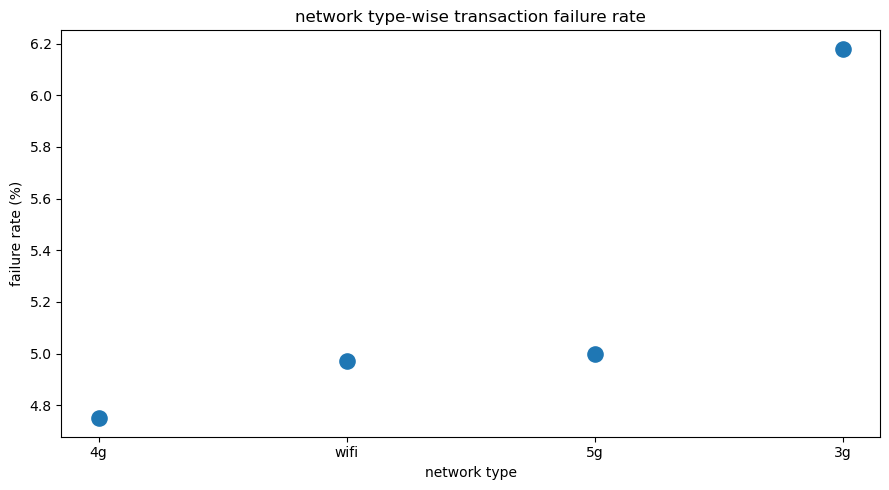

In [90]:
network_analysis = network_analysis.sort_values(
    "failure_rate"
)

plt.figure(figsize=(9, 5))

plt.scatter(
    network_analysis["network_type"],
    network_analysis["failure_rate"],
    s=120
)

plt.xlabel("network type")
plt.ylabel("failure rate (%)")
plt.title("network type-wise transaction failure rate")

plt.tight_layout()
plt.show()

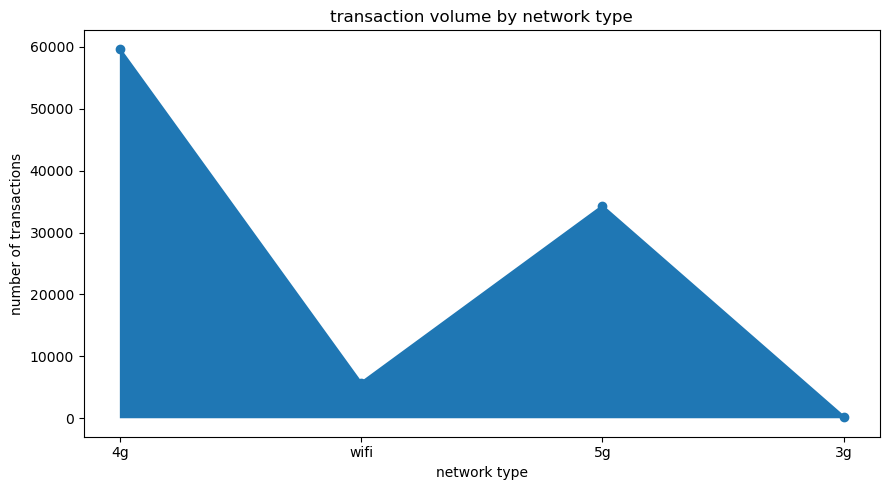

In [91]:
plt.figure(figsize=(9, 5))

plt.fill_between(
    network_analysis["network_type"],
    network_analysis["total_transactions"]
)

plt.plot(
    network_analysis["network_type"],
    network_analysis["total_transactions"],
    marker="o"
)

plt.xlabel("network type")
plt.ylabel("number of transactions")
plt.title("transaction volume by network type")

plt.tight_layout()
plt.show()

In [92]:
network_analysis.sort_values(
    "failure_rate",
    ascending=False
)[[
    "network_type",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "success_rate",
    "failure_rate",
    "total_transaction_value"
]]

,network_type,total_transactions,successful_transactions,failed_transactions,success_rate,failure_rate,total_transaction_value
0,3g,275,258,17,93.82,6.18,6.809347e+06
2,5g,34298,32583,1715,95.00,5.00,8.599629e+08
3,wifi,5750,5464,286,95.03,4.97,1.441856e+08
1,4g,59677,56843,2834,95.25,4.75,1.498610e+09


In [93]:
os_data = pd.read_sql("""
select
    device_id,
    operating_system
from devices;
""", conn)

df = df.drop(columns=["operating_system"], errors="ignore")

df = df.merge(
    os_data,
    on="device_id",
    how="left"
)

df[["device_id", "operating_system"]].head()

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\3758802485.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  os_data = pd.read_sql("""


,device_id,operating_system
0,519,android
1,8157,ios
2,8238,android
3,5661,android
4,10811,android


In [94]:
print("operating_system column exists:", "operating_system" in df.columns)
print(df["operating_system"].value_counts())

operating_system column exists: True
operating_system
android    74671
ios        24785
other        544
Name: count, dtype: int64


In [95]:
os_analysis = (
    df.groupby("operating_system")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

os_analysis["success_rate"] = (
    os_analysis["successful_transactions"]
    / os_analysis["total_transactions"]
    * 100
).round(2)

os_analysis["failure_rate"] = (
    os_analysis["failed_transactions"]
    / os_analysis["total_transactions"]
    * 100
).round(2)

os_analysis

,operating_system,total_transactions,successful_transactions,failed_transactions,total_transaction_value,success_rate,failure_rate
0,android,74671,71027,3644,1.874683e+09,95.12,4.88
1,ios,24785,23599,1186,6.219685e+08,95.21,4.79
2,other,544,522,22,1.291684e+07,95.96,4.04


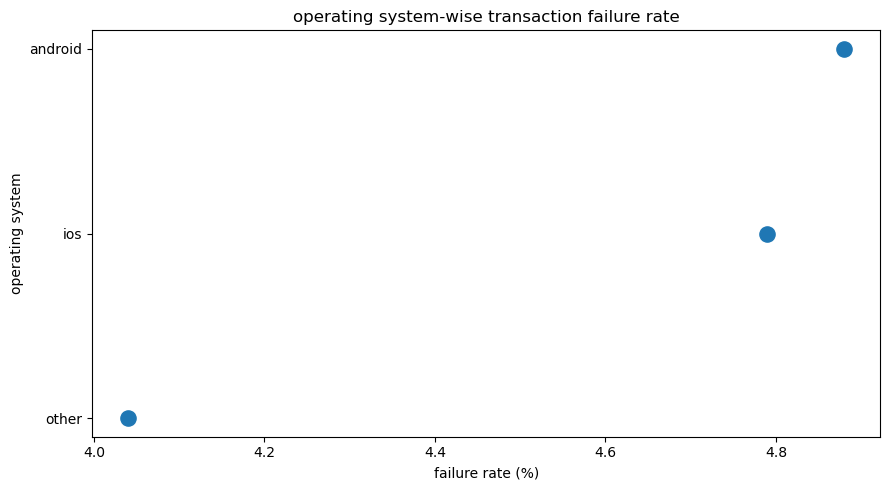

In [96]:
#OS failure rate
os_analysis = os_analysis.sort_values(
    "failure_rate",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.scatter(
    os_analysis["failure_rate"],
    os_analysis["operating_system"],
    s=120
)

plt.xlabel("failure rate (%)")
plt.ylabel("operating system")
plt.title("operating system-wise transaction failure rate")

plt.tight_layout()
plt.show()

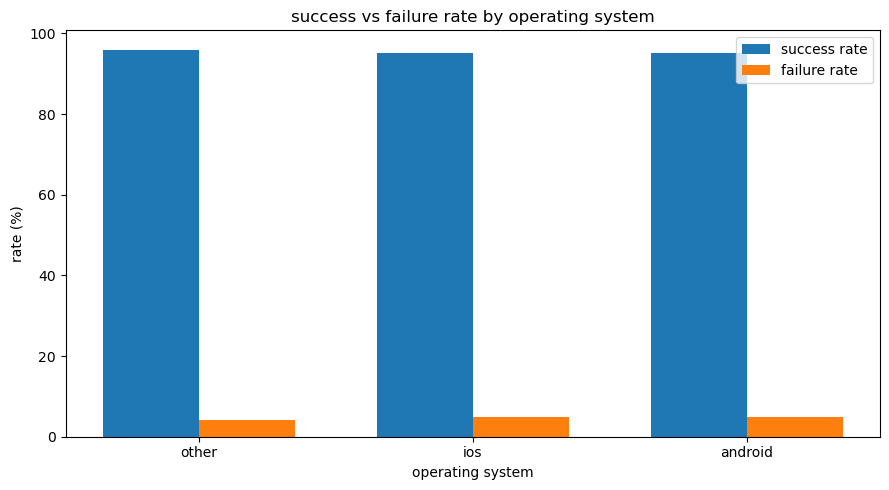

In [97]:
x = np.arange(len(os_analysis))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    os_analysis["success_rate"],
    width,
    label="success rate"
)

plt.bar(
    x + width / 2,
    os_analysis["failure_rate"],
    width,
    label="failure rate"
)

plt.xticks(
    x,
    os_analysis["operating_system"]
)

plt.xlabel("operating system")
plt.ylabel("rate (%)")
plt.title("success vs failure rate by operating system")
plt.legend()

plt.tight_layout()
plt.show()

In [98]:
os_analysis.sort_values(
    "failure_rate",
    ascending=False
)[[
    "operating_system",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "success_rate",
    "failure_rate",
    "total_transaction_value"
]]

,operating_system,total_transactions,successful_transactions,failed_transactions,success_rate,failure_rate,total_transaction_value
0,android,74671,71027,3644,95.12,4.88,1.874683e+09
1,ios,24785,23599,1186,95.21,4.79,6.219685e+08
2,other,544,522,22,95.96,4.04,1.291684e+07


In [99]:
#region wise analysis
region_analysis = (
    df.groupby("region")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

region_analysis["success_rate"] = (
    region_analysis["successful_transactions"]
    / region_analysis["total_transactions"]
    * 100
).round(2)

region_analysis["failure_rate"] = (
    region_analysis["failed_transactions"]
    / region_analysis["total_transactions"]
    * 100
).round(2)

region_analysis

,region,total_transactions,successful_transactions,failed_transactions,total_transaction_value,success_rate,failure_rate
0,Central,5044,4803,241,1.267703e+08,95.22,4.78
1,East,15039,14243,796,3.749909e+08,94.71,5.29
2,North,34948,33331,1617,8.792972e+08,95.37,4.63
3,North East,4982,4724,258,1.239142e+08,94.82,5.18
4,South,19866,18941,925,4.991535e+08,95.34,4.66
5,West,20121,19106,1015,5.054421e+08,94.96,5.04


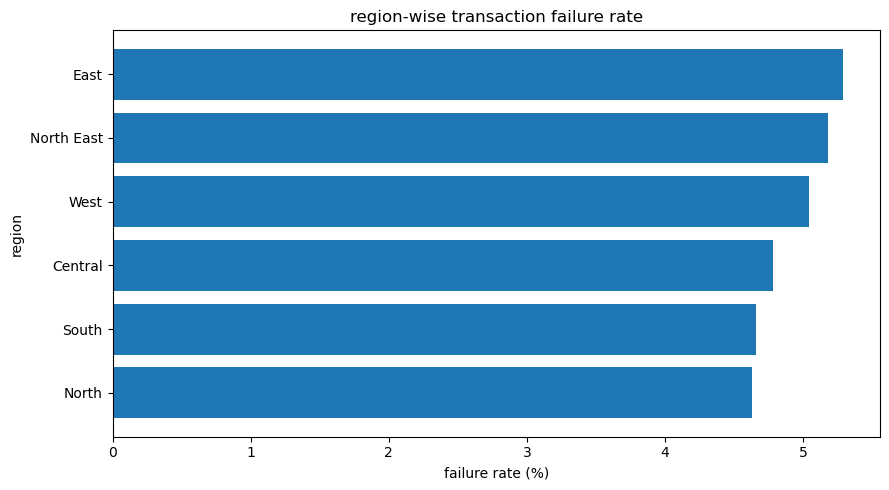

In [100]:
#failure rate
region_analysis = region_analysis.sort_values(
    "failure_rate",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    region_analysis["region"],
    region_analysis["failure_rate"]
)

plt.xlabel("failure rate (%)")
plt.ylabel("region")
plt.title("region-wise transaction failure rate")

plt.tight_layout()
plt.show()

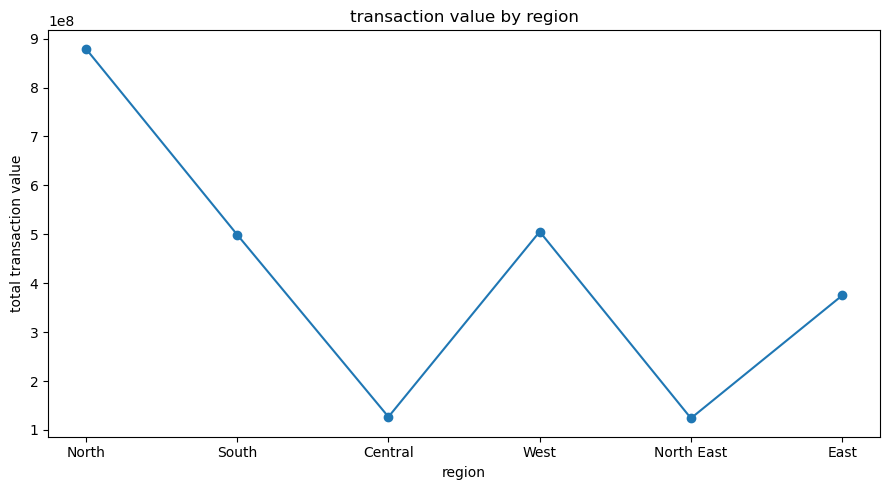

In [101]:
plt.figure(figsize=(9, 5))

plt.plot(
    region_analysis["region"],
    region_analysis["total_transaction_value"],
    marker="o"
)

plt.xlabel("region")
plt.ylabel("total transaction value")
plt.title("transaction value by region")

plt.tight_layout()
plt.show()

In [102]:
region_analysis.sort_values(
    "failure_rate",
    ascending=False
)[[
    "region",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "success_rate",
    "failure_rate",
    "total_transaction_value"
]]

,region,total_transactions,successful_transactions,failed_transactions,success_rate,failure_rate,total_transaction_value
1,East,15039,14243,796,94.71,5.29,3.749909e+08
3,North East,4982,4724,258,94.82,5.18,1.239142e+08
5,West,20121,19106,1015,94.96,5.04,5.054421e+08
0,Central,5044,4803,241,95.22,4.78,1.267703e+08
4,South,19866,18941,925,95.34,4.66,4.991535e+08
2,North,34948,33331,1617,95.37,4.63,8.792972e+08


In [103]:
#Daily Analysis
df["date"] = df["transaction_date"].dt.date

daily_analysis = (
    df.groupby("date")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

daily_analysis["failure_rate"] = (
    daily_analysis["failed_transactions"]
    / daily_analysis["total_transactions"]
    * 100
).round(2)

daily_analysis["success_rate"] = (
    daily_analysis["successful_transactions"]
    / daily_analysis["total_transactions"]
    * 100
).round(2)

daily_analysis.head()

,date,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate,success_rate
0,2025-01-01,295,280,15,7630813.98,5.08,94.92
1,2025-01-02,264,251,13,6929666.25,4.92,95.08
2,2025-01-03,306,289,17,7210919.79,5.56,94.44
3,2025-01-04,268,254,14,6587506.43,5.22,94.78
4,2025-01-05,290,279,11,7509756.59,3.79,96.21


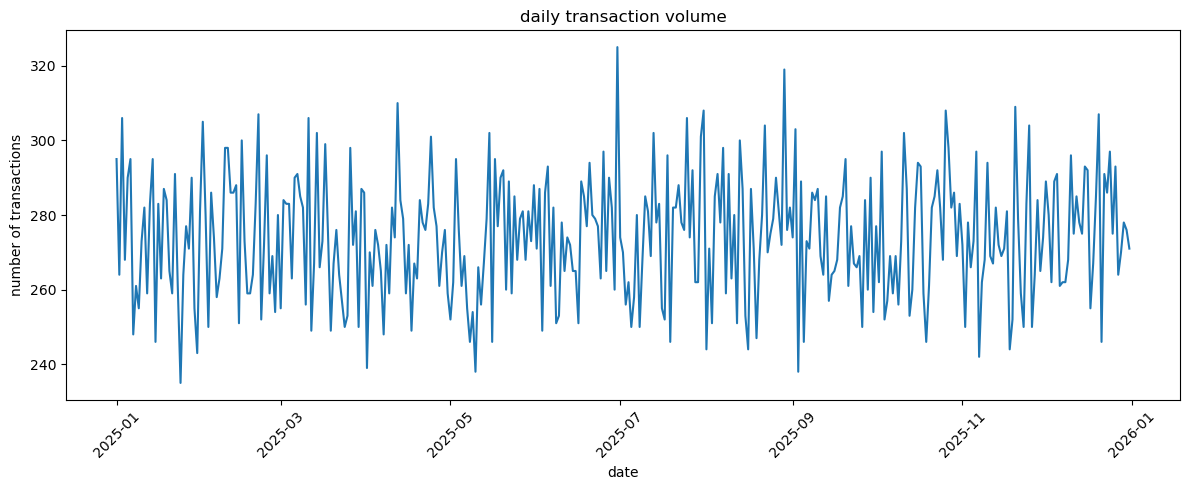

In [104]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_analysis["date"],
    daily_analysis["total_transactions"]
)

plt.xlabel("date")
plt.ylabel("number of transactions")
plt.title("daily transaction volume")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

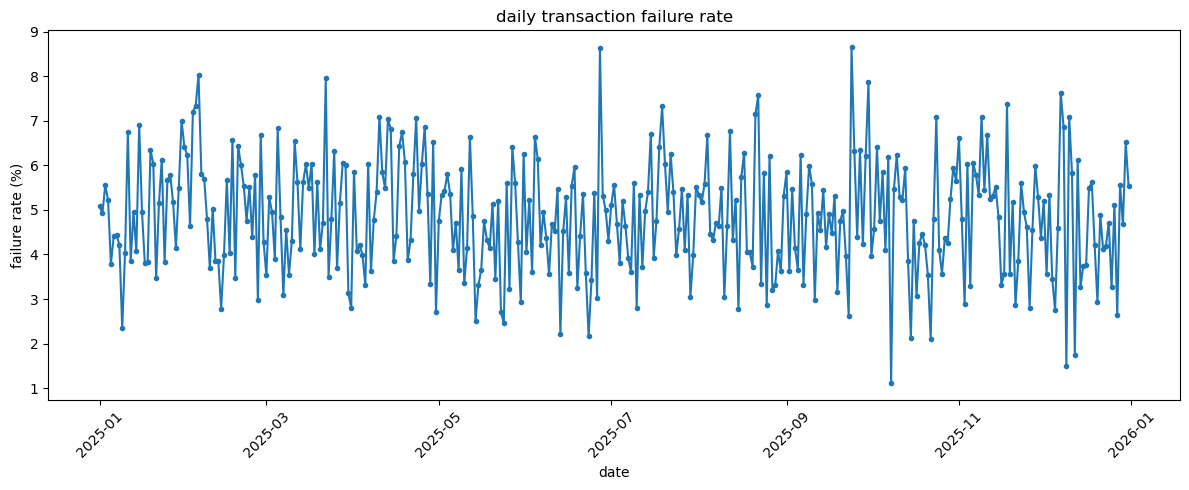

In [105]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_analysis["date"],
    daily_analysis["failure_rate"],
    marker="o",
    markersize=3
)

plt.xlabel("date")
plt.ylabel("failure rate (%)")
plt.title("daily transaction failure rate")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [106]:
#highest failure days
daily_analysis.sort_values(
    "failure_rate",
    ascending=False
).head(10)

,date,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate,success_rate
266,2025-09-24,266,243,23,6780682.67,8.65,91.35
177,2025-06-27,290,265,25,7390182.30,8.62,91.38
35,2025-02-05,274,252,22,6819590.97,8.03,91.97
80,2025-03-22,264,243,21,6499730.28,7.95,92.05
272,2025-09-30,254,234,20,6508134.07,7.87,92.13
340,2025-12-07,262,242,20,6066861.32,7.63,92.37
233,2025-08-22,304,281,23,7844414.90,7.57,92.43
321,2025-11-18,244,226,18,6240219.86,7.38,92.62
34,2025-02-04,286,265,21,7190659.34,7.34,92.66
199,2025-07-19,246,228,18,6385749.47,7.32,92.68


In [107]:
#highest transaction-volume days
daily_analysis.sort_values(
    "total_transactions",
    ascending=False
).head(10)

,date,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate,success_rate
180,2025-06-30,325,311,14,7852189.90,4.31,95.69
240,2025-08-29,319,306,13,8040415.77,4.08,95.92
101,2025-04-12,310,293,17,7555537.87,5.48,94.52
323,2025-11-20,309,293,16,7732604.95,5.18,94.82
298,2025-10-26,308,297,11,7826214.81,3.57,96.43
211,2025-07-31,308,291,17,7529015.48,5.52,94.48
353,2025-12-20,307,298,9,7795338.30,2.93,97.07
51,2025-02-21,307,290,17,7344255.41,5.54,94.46
2,2025-01-03,306,289,17,7210919.79,5.56,94.44
69,2025-03-11,306,286,20,7127528.65,6.54,93.46


In [108]:
#Hour + failure category analysis
hour_failure_analysis = (
    df[df["transaction_status"] == "failed"]
    .groupby(["hour", "failure_category"])
    .size()
    .reset_index(name="failed_transactions")
)

hour_failure_analysis.head()

,hour,failure_category,failed_transactions
0,0,bank-side failure,32
1,0,insufficient balance,14
2,0,invalid upi pin,20
3,0,limit exceeded,18
4,0,network failure,30


In [109]:
hour_failure_total = (
    df[df["transaction_status"] == "failed"]
    .groupby("hour")
    .size()
    .reset_index(name="failed_transactions")
)

hour_failure_total

,hour,failed_transactions
0,0,194
1,1,235
2,2,203
3,3,184
4,4,178
5,5,225
6,6,194
7,7,195
8,8,183
9,9,194


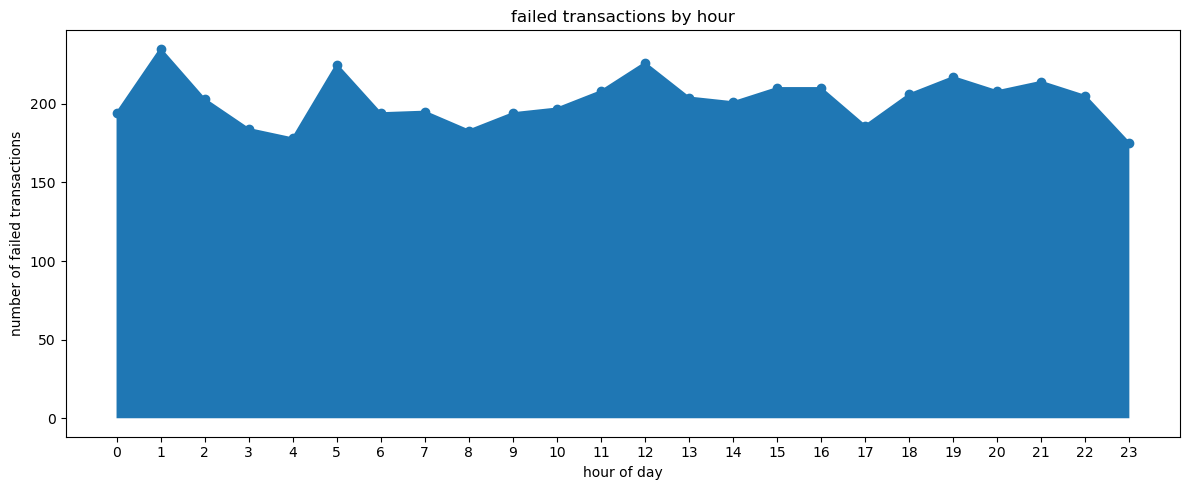

In [110]:
#failure count by hr
plt.figure(figsize=(12, 5))

plt.fill_between(
    hour_failure_total["hour"],
    hour_failure_total["failed_transactions"]
)

plt.plot(
    hour_failure_total["hour"],
    hour_failure_total["failed_transactions"],
    marker="o"
)

plt.xlabel("hour of day")
plt.ylabel("number of failed transactions")
plt.title("failed transactions by hour")

plt.xticks(range(24))

plt.tight_layout()
plt.show()

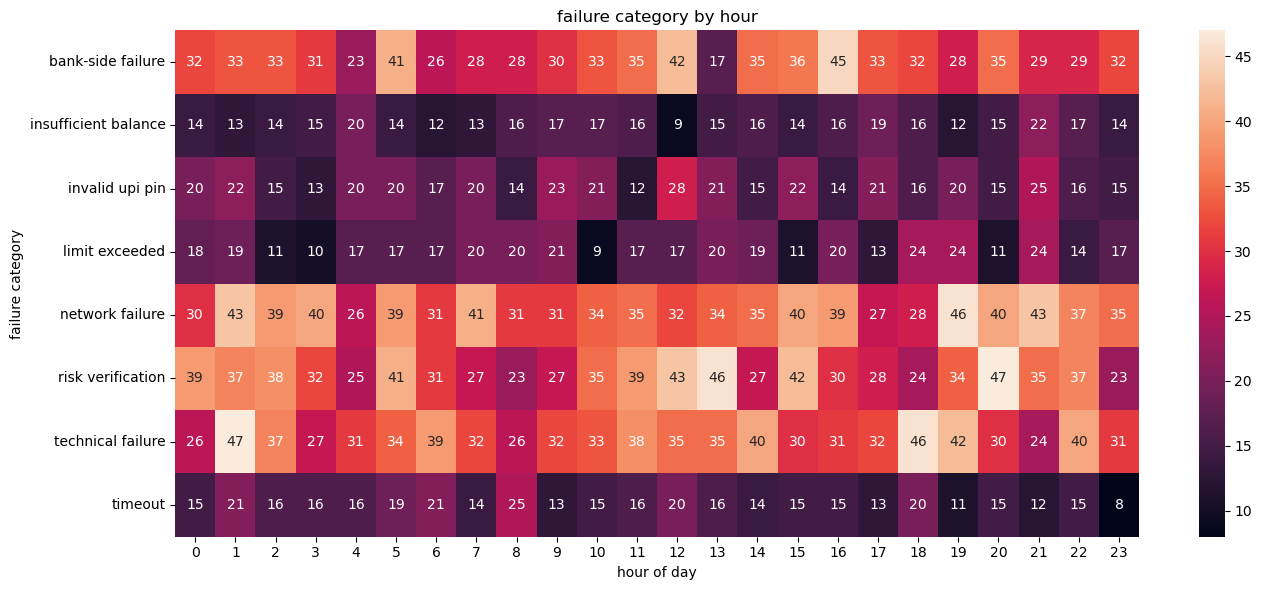

In [111]:
#failure reason
hour_category_pivot = (
    hour_failure_analysis
    .pivot(
        index="failure_category",
        columns="hour",
        values="failed_transactions"
    )
    .fillna(0)
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    hour_category_pivot,
    annot=True,
    fmt=".0f"
)

plt.title("failure category by hour")
plt.xlabel("hour of day")
plt.ylabel("failure category")

plt.tight_layout()
plt.show()

In [112]:
hour_failure_analysis.sort_values(
    "failed_transactions",
    ascending=False
).head(15)

,hour,failure_category,failed_transactions
14,1,technical failure,47
165,20,risk verification,47
109,13,risk verification,46
156,19,network failure,46
150,18,technical failure,46
128,16,bank-side failure,45
101,12,risk verification,43
12,1,network failure,43
172,21,network failure,43
125,15,risk verification,42


In [113]:
#load trans. attempts
attempts = pd.read_sql("""
select *
from transaction_attempts;
""", conn)

print("rows:", attempts.shape[0])
print("columns:", attempts.shape[1])

attempts.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\1265588603.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  attempts = pd.read_sql("""


rows: 110000
columns: 6


,attempt_id,transaction_id,attempt_number,attempt_time,attempt_status,failure_reason_id
0,1,1,1,2025-06-14 22:41:52.572596,success,NaN
1,2,2,1,2025-01-07 11:49:36.221277,success,NaN
2,3,3,1,2025-06-07 04:59:32.594617,success,NaN
3,4,4,1,2025-10-27 15:27:12.347426,success,NaN
4,5,7,1,2025-04-26 19:51:33.652314,success,NaN


In [114]:
attempts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110000 entries, 0 to 109999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   attempt_id         110000 non-null  int64         
 1   transaction_id     110000 non-null  int64         
 2   attempt_number     110000 non-null  int64         
 3   attempt_time       110000 non-null  datetime64[ns]
 4   attempt_status     110000 non-null  object        
 5   failure_reason_id  14852 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 5.0+ MB


In [115]:
attempts["attempt_status"].value_counts()

attempt_status
success    95148
failed     14852
Name: count, dtype: int64

In [116]:
attempts["attempt_status"].value_counts(
    normalize=True
).mul(100).round(2)

attempt_status
success    86.5
failed     13.5
Name: proportion, dtype: float64

In [117]:
#attempt wise success/failure
attempt_analysis = (
    attempts.groupby("attempt_status")
    .agg(
        total_attempts=("attempt_id", "count")
    )
    .reset_index()
)

attempt_analysis["percentage"] = (
    attempt_analysis["total_attempts"]
    / attempt_analysis["total_attempts"].sum()
    * 100
).round(2)

attempt_analysis

,attempt_status,total_attempts,percentage
0,failed,14852,13.5
1,success,95148,86.5


In [118]:
attempts["attempt_number"].value_counts().sort_index()

attempt_number
1    100000
2     10000
Name: count, dtype: int64

In [119]:
attempt_type_analysis = (
    attempts.groupby("attempt_number")
    .agg(
        total_attempts=("attempt_id", "count"),
        successful_attempts=("attempt_status", lambda x: (x == "success").sum()),
        failed_attempts=("attempt_status", lambda x: (x == "failed").sum())
    )
    .reset_index()
)

attempt_type_analysis["success_rate"] = (
    attempt_type_analysis["successful_attempts"]
    / attempt_type_analysis["total_attempts"]
    * 100
).round(2)

attempt_type_analysis["failure_rate"] = (
    attempt_type_analysis["failed_attempts"]
    / attempt_type_analysis["total_attempts"]
    * 100
).round(2)

attempt_type_analysis

,attempt_number,total_attempts,successful_attempts,failed_attempts,success_rate,failure_rate
0,1,100000,88024,11976,88.02,11.98
1,2,10000,7124,2876,71.24,28.76


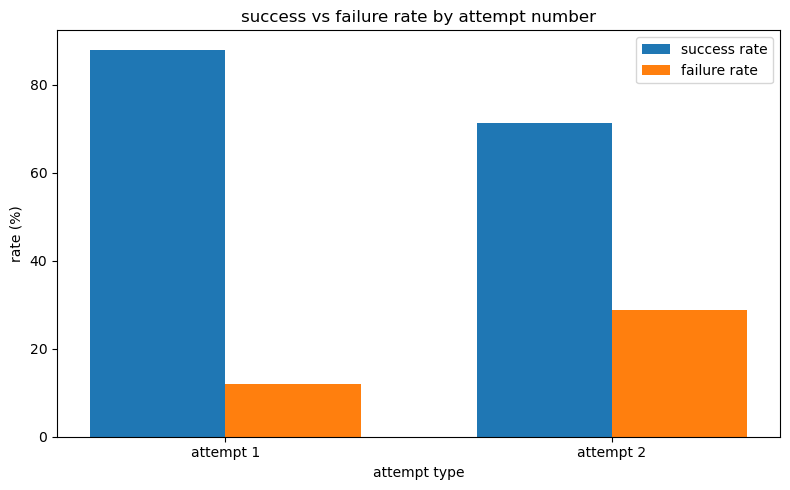

In [120]:
x = np.arange(len(attempt_type_analysis))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    attempt_type_analysis["success_rate"],
    width,
    label="success rate"
)

plt.bar(
    x + width / 2,
    attempt_type_analysis["failure_rate"],
    width,
    label="failure rate"
)

plt.xticks(
    x,
    [
        f"attempt {n}"
        for n in attempt_type_analysis["attempt_number"]
    ]
)

plt.xlabel("attempt type")
plt.ylabel("rate (%)")
plt.title("success vs failure rate by attempt number")
plt.legend()

plt.tight_layout()
plt.show()

In [121]:
retry_recovery = (
    attempts
    .pivot_table(
        index="transaction_id",
        columns="attempt_number",
        values="attempt_status",
        aggfunc="first"
    )
    .reset_index()
)

retry_recovery.head()

attempt_number,transaction_id,1,2
0,1,success,NaN
1,2,success,NaN
2,3,success,NaN
3,4,success,NaN
4,5,failed,NaN


In [122]:
retry_recovery["recovered_on_retry"] = (
    (retry_recovery[1] == "failed") &
    (retry_recovery[2] == "success")
)

retry_recovery["failed_initially"] = (
    retry_recovery[1] == "failed"
)

retry_recovery.head()

attempt_number,transaction_id,1,2,recovered_on_retry,failed_initially
0,1,success,NaN,False,False
1,2,success,NaN,False,False
2,3,success,NaN,False,False
3,4,success,NaN,False,False
4,5,failed,NaN,False,True


In [123]:
#recovery rate
initial_failed = retry_recovery[
    retry_recovery["failed_initially"] == True
]

recovered_transactions = initial_failed[
    initial_failed["recovered_on_retry"] == True
]

retry_recovery_rate = (
    len(recovered_transactions)
    / len(initial_failed)
    * 100
)

print(
    "initially failed transactions:",
    len(initial_failed)
)

print(
    "recovered on retry:",
    len(recovered_transactions)
)

print(
    "retry recovery rate:",
    round(retry_recovery_rate, 2),
    "%"
)

initially failed transactions: 11976
recovered on retry: 7124
retry recovery rate: 59.49 %


In [124]:
initial_failed["retry_outcome"] = np.where(
    initial_failed["recovered_on_retry"],
    "recovered",
    "failed again"
)

retry_outcome = (
    initial_failed["retry_outcome"]
    .value_counts()
)

retry_outcome

C:\Users\HP\AppData\Local\Temp\ipykernel_10264\2895986029.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  initial_failed["retry_outcome"] = np.where(


retry_outcome
recovered       7124
failed again    4852
Name: count, dtype: int64

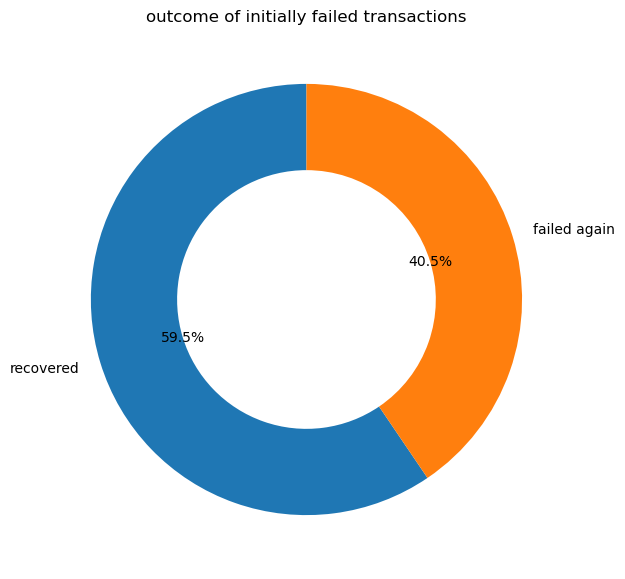

In [125]:
plt.figure(figsize=(7, 7))

plt.pie(
    retry_outcome.values,
    labels=retry_outcome.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.4)
)

plt.title("outcome of initially failed transactions")
plt.show()

In [126]:
retry_recovery_detail = retry_recovery.merge(
    df[
        [
            "transaction_id",
            "failure_category",
            "failure_reason"
        ]
    ].drop_duplicates("transaction_id"),
    on="transaction_id",
    how="left"
)

category_recovery = (
    retry_recovery_detail[
        retry_recovery_detail["failed_initially"] == True
    ]
    .groupby("failure_category")
    .agg(
        initially_failed=("transaction_id", "count"),
        recovered_on_retry=("recovered_on_retry", "sum")
    )
    .reset_index()
)

category_recovery["recovery_rate"] = (
    category_recovery["recovered_on_retry"]
    / category_recovery["initially_failed"]
    * 100
).round(2)

category_recovery.sort_values(
    "recovery_rate",
    ascending=False
)

,failure_category,initially_failed,recovered_on_retry,recovery_rate
0,bank-side failure,766,0,0.0
1,insufficient balance,366,0,0.0
2,invalid upi pin,445,0,0.0
3,limit exceeded,410,0,0.0
4,network failure,856,0,0.0
5,risk verification,810,0,0.0
6,technical failure,818,0,0.0
7,timeout,381,0,0.0


In [127]:
#user wise trans. analysis
user_analysis = (
    df.groupby("user_id")
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum"),
        average_transaction_value=("transaction_amount", "mean")
    )
    .reset_index()
)

user_analysis["success_rate"] = (
    user_analysis["successful_transactions"]
    / user_analysis["total_transactions"]
    * 100
).round(2)

user_analysis["failure_rate"] = (
    user_analysis["failed_transactions"]
    / user_analysis["total_transactions"]
    * 100
).round(2)

user_analysis.head()

,user_id,total_transactions,successful_transactions,failed_transactions,total_transaction_value,average_transaction_value,success_rate,failure_rate
0,1,12,12,0,423276.27,35273.022500,100.00,0.00
1,2,10,10,0,202815.03,20281.503000,100.00,0.00
2,3,7,7,0,175933.80,25133.400000,100.00,0.00
3,4,8,7,1,148971.93,18621.491250,87.50,12.50
4,5,13,11,2,335792.62,25830.201538,84.62,15.38


In [128]:
user_analysis["activity_level"] = pd.cut(
    user_analysis["total_transactions"],
    bins=[0, 5, 10, 20, float("inf")],
    labels=[
        "low activity",
        "medium activity",
        "high activity",
        "very high activity"
    ]
)

user_analysis["activity_level"].value_counts()

activity_level
medium activity       5151
high activity         4166
low activity           673
very high activity       7
Name: count, dtype: int64

In [129]:
activity_analysis = (
    user_analysis.groupby("activity_level", observed=False)
    .agg(
        users=("user_id", "count"),
        total_transactions=("total_transactions", "sum"),
        average_failure_rate=("failure_rate", "mean"),
        total_transaction_value=("total_transaction_value", "sum")
    )
    .reset_index()
)

activity_analysis["average_failure_rate"] = (
    activity_analysis["average_failure_rate"]
    .round(2)
)

activity_analysis

,activity_level,users,total_transactions,average_failure_rate,total_transaction_value
0,low activity,673,2952,5.01,7.426361e+07
1,medium activity,5151,42767,4.81,1.077045e+09
2,high activity,4166,54129,4.85,1.354595e+09
3,very high activity,7,152,3.99,3.664615e+06


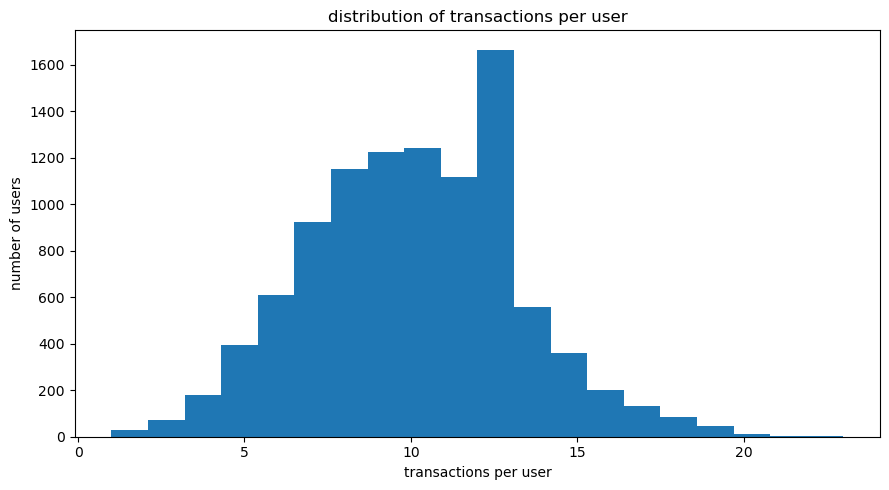

In [130]:
plt.figure(figsize=(9, 5))

plt.hist(
    user_analysis["total_transactions"],
    bins=20
)

plt.xlabel("transactions per user")
plt.ylabel("number of users")
plt.title("distribution of transactions per user")

plt.tight_layout()
plt.show()

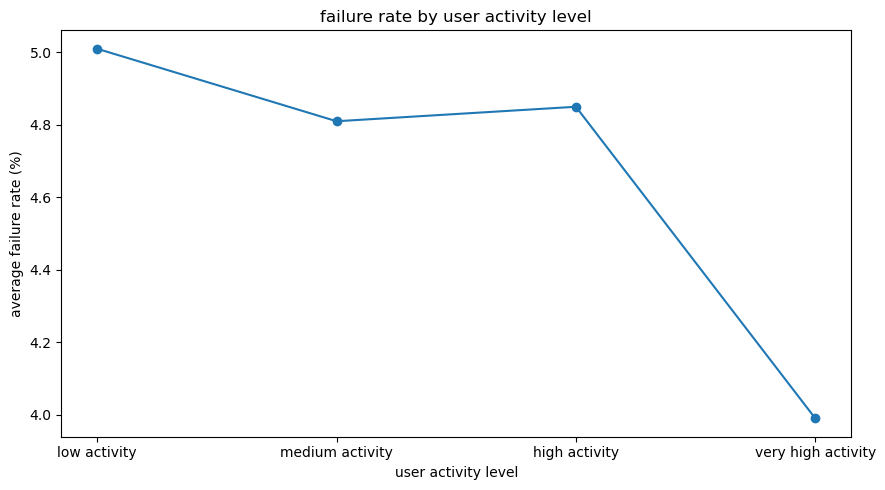

In [131]:
plt.figure(figsize=(9, 5))

plt.plot(
    activity_analysis["activity_level"].astype(str),
    activity_analysis["average_failure_rate"],
    marker="o"
)

plt.xlabel("user activity level")
plt.ylabel("average failure rate (%)")
plt.title("failure rate by user activity level")

plt.tight_layout()
plt.show()

In [132]:
high_failure_users = (
    user_analysis[
        user_analysis["total_transactions"] >= 10
    ]
    .sort_values(
        "failure_rate",
        ascending=False
    )
)

high_failure_users.head(10)

,user_id,total_transactions,successful_transactions,failed_transactions,total_transaction_value,average_transaction_value,success_rate,failure_rate,activity_level
2886,2887,12,7,5,302684.39,25223.699167,58.33,41.67,high activity
7801,7804,10,6,4,283298.45,28329.845000,60.00,40.00,medium activity
1416,1417,11,7,4,381724.49,34702.226364,63.64,36.36,high activity
2943,2944,11,7,4,268169.86,24379.078182,63.64,36.36,high activity
5555,5557,12,8,4,313240.90,26103.408333,66.67,33.33,high activity
5517,5519,12,8,4,285433.53,23786.127500,66.67,33.33,high activity
3023,3024,13,9,4,412833.24,31756.403077,69.23,30.77,high activity
8461,8464,10,7,3,286315.14,28631.514000,70.00,30.00,medium activity
6452,6455,10,7,3,207650.32,20765.032000,70.00,30.00,medium activity
272,273,10,7,3,230877.56,23087.756000,70.00,30.00,medium activity


In [133]:
#bank failure category
bank_failure_analysis = (
    df[df["transaction_status"] == "failed"]
    .groupby(["bank_name", "failure_category"])
    .size()
    .reset_index(name="failed_transactions")
)

bank_failure_analysis.head()

,bank_name,failure_category,failed_transactions
0,AU Small Finance Bank,bank-side failure,56
1,AU Small Finance Bank,insufficient balance,30
2,AU Small Finance Bank,invalid upi pin,24
3,AU Small Finance Bank,limit exceeded,20
4,AU Small Finance Bank,network failure,57


In [134]:
bank_failure_pivot = (
    bank_failure_analysis
    .pivot(
        index="bank_name",
        columns="failure_category",
        values="failed_transactions"
    )
    .fillna(0)
)

bank_failure_pivot

failure_category,bank-side failure,insufficient balance,invalid upi pin,limit exceeded,network failure,risk verification,technical failure,timeout
bank_name,,,,,,,,
AU Small Finance Bank,56,30,24,20,57,44,66,33
Axis Bank,50,24,35,30,57,49,47,20
Bank of Baroda,43,26,31,23,58,58,46,20
Canara Bank,47,30,34,34,54,55,47,40
Federal Bank,47,22,24,26,52,47,61,14
HDFC Bank,45,21,32,26,51,46,58,18
ICICI Bank,53,18,27,31,62,55,56,27
IDFC FIRST Bank,47,22,26,25,66,59,51,18
IndusInd Bank,51,19,39,39,52,60,68,28


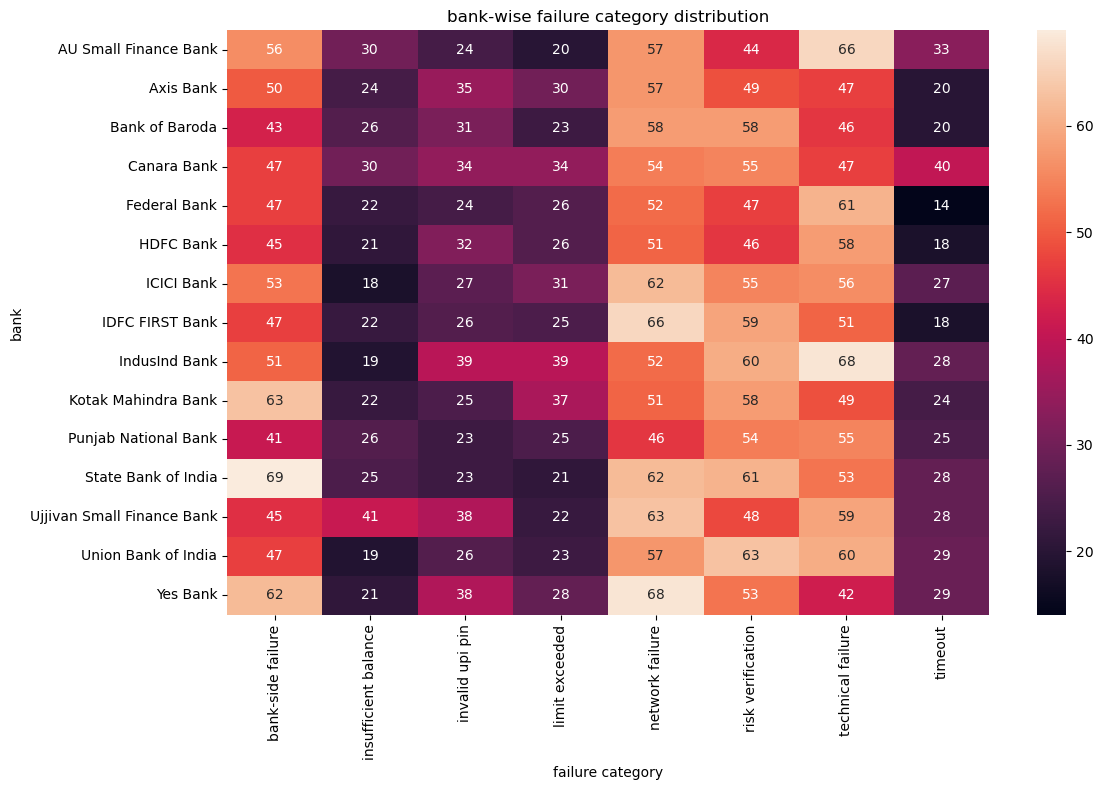

In [135]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    bank_failure_pivot,
    annot=True,
    fmt=".0f"
)

plt.title("bank-wise failure category distribution")
plt.xlabel("failure category")
plt.ylabel("bank")

plt.tight_layout()
plt.show()

In [136]:
bank_failure_percentage = (
    bank_failure_pivot
    .div(bank_failure_pivot.sum(axis=1), axis=0)
    * 100
)

bank_failure_percentage = bank_failure_percentage.round(2)

bank_failure_percentage

failure_category,bank-side failure,insufficient balance,invalid upi pin,limit exceeded,network failure,risk verification,technical failure,timeout
bank_name,,,,,,,,
AU Small Finance Bank,16.97,9.09,7.27,6.06,17.27,13.33,20.00,10.00
Axis Bank,16.03,7.69,11.22,9.62,18.27,15.71,15.06,6.41
Bank of Baroda,14.10,8.52,10.16,7.54,19.02,19.02,15.08,6.56
Canara Bank,13.78,8.80,9.97,9.97,15.84,16.13,13.78,11.73
Federal Bank,16.04,7.51,8.19,8.87,17.75,16.04,20.82,4.78
HDFC Bank,15.15,7.07,10.77,8.75,17.17,15.49,19.53,6.06
ICICI Bank,16.11,5.47,8.21,9.42,18.84,16.72,17.02,8.21
IDFC FIRST Bank,14.97,7.01,8.28,7.96,21.02,18.79,16.24,5.73
IndusInd Bank,14.33,5.34,10.96,10.96,14.61,16.85,19.10,7.87


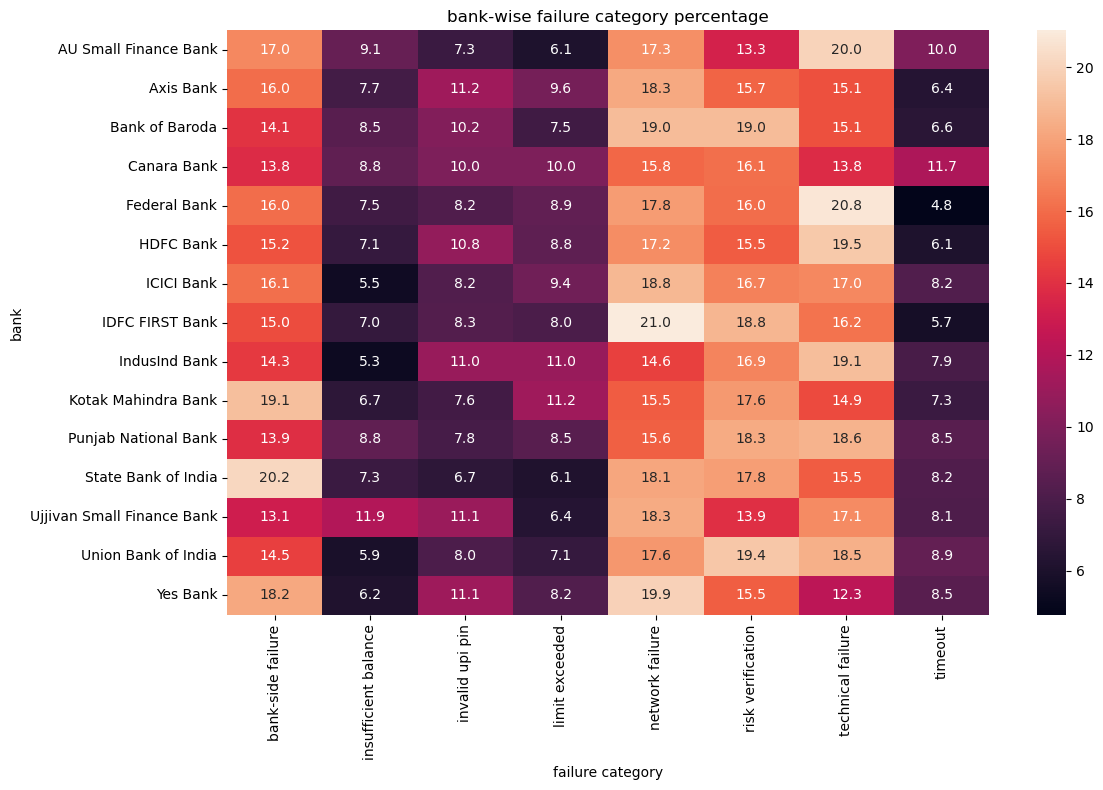

In [137]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    bank_failure_percentage,
    annot=True,
    fmt=".1f"
)

plt.title("bank-wise failure category percentage")
plt.xlabel("failure category")
plt.ylabel("bank")

plt.tight_layout()
plt.show()

In [138]:
dominant_failure_by_bank = (
    bank_failure_percentage
    .idxmax(axis=1)
    .reset_index()
)

dominant_failure_by_bank.columns = [
    "bank_name",
    "dominant_failure_category"
]

dominant_failure_by_bank

,bank_name,dominant_failure_category
0,AU Small Finance Bank,technical failure
1,Axis Bank,network failure
2,Bank of Baroda,network failure
3,Canara Bank,risk verification
4,Federal Bank,technical failure
5,HDFC Bank,technical failure
6,ICICI Bank,network failure
7,IDFC FIRST Bank,network failure
8,IndusInd Bank,technical failure
9,Kotak Mahindra Bank,bank-side failure


In [139]:
#Merchant-channel analyis
merchant_channel_analysis = (
    df.groupby(["merchant_category", "payment_channel"])
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

merchant_channel_analysis["failure_rate"] = (
    merchant_channel_analysis["failed_transactions"]
    / merchant_channel_analysis["total_transactions"]
    * 100
).round(2)

merchant_channel_analysis

,merchant_category,payment_channel,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate
0,E-commerce,collect_request,2857,2708,149,71479638.53,5.22
1,E-commerce,qr,2854,2714,140,70447240.26,4.91
2,E-commerce,upi_app,2706,2574,132,67837587.35,4.88
3,E-commerce,upi_id,2817,2701,116,70959289.46,4.12
4,Education,collect_request,2631,2504,127,65038185.34,4.83
5,Education,qr,2630,2513,117,65104956.55,4.45
6,Education,upi_app,2698,2560,138,67086928.74,5.11
7,Education,upi_id,2686,2561,125,66293220.47,4.65
8,Fuel,collect_request,2812,2672,140,68772551.28,4.98
9,Fuel,qr,2718,2595,123,68156542.08,4.53


In [140]:
merchant_channel_pivot = (
    merchant_channel_analysis
    .pivot(
        index="merchant_category",
        columns="payment_channel",
        values="failure_rate"
    )
)

merchant_channel_pivot

payment_channel,collect_request,qr,upi_app,upi_id
merchant_category,,,,
E-commerce,5.22,4.91,4.88,4.12
Education,4.83,4.45,5.11,4.65
Fuel,4.98,4.53,4.07,4.40
Government Services,5.00,4.78,5.19,4.75
Grocery,5.28,5.43,5.06,4.59
Pharmacy,5.50,4.90,4.84,5.17
Restaurant,4.85,5.38,5.42,4.85
Retail,5.17,4.83,4.56,5.41
Travel,4.40,4.67,4.69,4.76


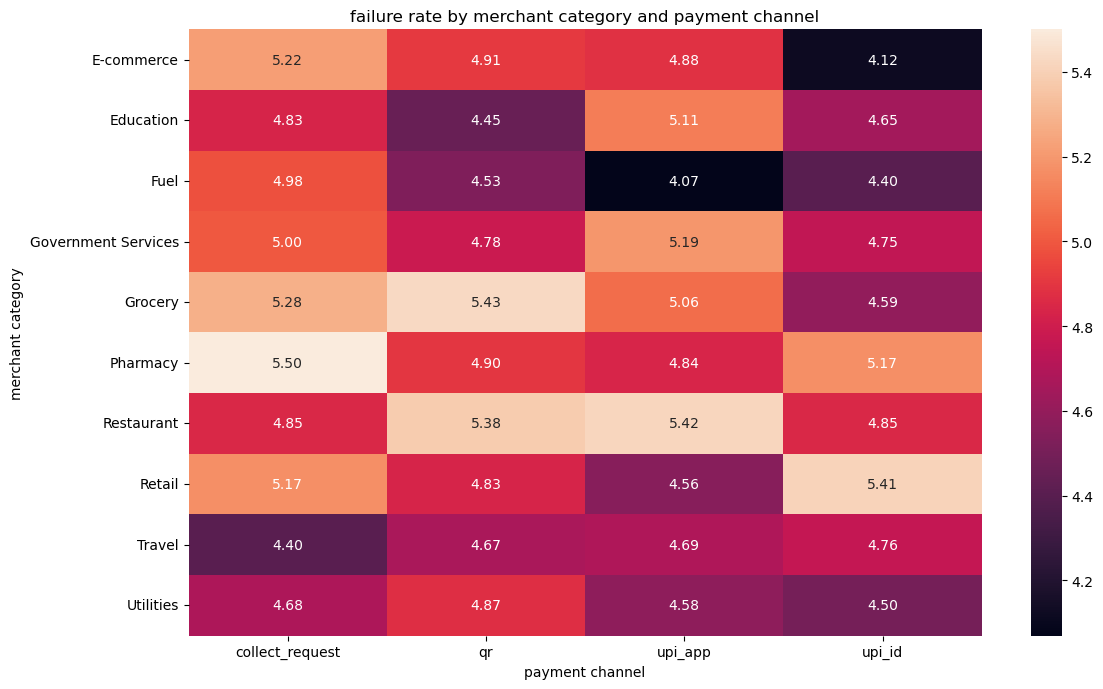

In [141]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    merchant_channel_pivot,
    annot=True,
    fmt=".2f"
)

plt.title("failure rate by merchant category and payment channel")
plt.xlabel("payment channel")
plt.ylabel("merchant category")

plt.tight_layout()
plt.show()

In [142]:
merchant_channel_analysis.sort_values(
    "failure_rate",
    ascending=False
).head(15)

,merchant_category,payment_channel,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate
20,Pharmacy,collect_request,2072,1958,114,50980724.63,5.50
17,Grocery,qr,2653,2509,144,67759421.96,5.43
26,Restaurant,upi_app,2637,2494,143,66326167.25,5.42
31,Retail,upi_id,2368,2240,128,58964739.75,5.41
25,Restaurant,qr,2657,2514,143,66648077.98,5.38
16,Grocery,collect_request,2633,2494,139,65593621.42,5.28
0,E-commerce,collect_request,2857,2708,149,71479638.53,5.22
14,Government Services,upi_app,2352,2230,122,58009452.67,5.19
28,Retail,collect_request,2437,2311,126,61193485.32,5.17
23,Pharmacy,upi_id,2090,1982,108,52773796.37,5.17


In [143]:
merchant_channel_analysis.sort_values(
    "total_transactions",
    ascending=False
).head(15)

,merchant_category,payment_channel,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate
0,E-commerce,collect_request,2857,2708,149,71479638.53,5.22
1,E-commerce,qr,2854,2714,140,70447240.26,4.91
3,E-commerce,upi_id,2817,2701,116,70959289.46,4.12
8,Fuel,collect_request,2812,2672,140,68772551.28,4.98
10,Fuel,upi_app,2750,2638,112,70322116.81,4.07
9,Fuel,qr,2718,2595,123,68156542.08,4.53
2,E-commerce,upi_app,2706,2574,132,67837587.35,4.88
6,Education,upi_app,2698,2560,138,67086928.74,5.11
7,Education,upi_id,2686,2561,125,66293220.47,4.65
11,Fuel,upi_id,2681,2563,118,66738394.84,4.40


In [144]:
#city-Network analysis
city_network_analysis = (
    df.groupby(["city", "network_type"])
    .agg(
        total_transactions=("transaction_id", "count"),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

city_network_analysis["failure_rate"] = (
    city_network_analysis["failed_transactions"]
    / city_network_analysis["total_transactions"]
    * 100
).round(2)

city_network_analysis

,city,network_type,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate
0,Ahmedabad,3g,13,13,0,378195.80,0.00
1,Ahmedabad,4g,3037,2911,126,75291781.56,4.15
2,Ahmedabad,5g,1708,1614,94,42046969.65,5.50
3,Ahmedabad,wifi,313,297,16,8239758.51,5.11
4,Bengaluru,3g,17,17,0,433321.90,0.00
...,...,...,...,...,...,...,...
75,Rishikesh,wifi,285,265,20,6709222.07,7.02
76,Surat,3g,15,13,2,227569.33,13.33
77,Surat,4g,2909,2747,162,73563839.18,5.57
78,Surat,5g,1800,1701,99,45092545.05,5.50


In [145]:
city_network_pivot = (
    city_network_analysis
    .pivot(
        index="city",
        columns="network_type",
        values="failure_rate"
    )
)

city_network_pivot

network_type,3g,4g,5g,wifi
city,,,,
Ahmedabad,0.00,4.15,5.50,5.11
Bengaluru,0.00,4.23,5.00,5.88
Bhopal,12.50,4.92,4.37,5.39
Bhubaneswar,0.00,4.85,5.75,4.38
Chandigarh,6.67,4.81,4.64,4.66
Chennai,13.33,4.57,4.65,4.26
Dehradun,11.11,4.11,5.06,5.46
Delhi,12.50,5.40,4.73,4.30
Guwahati,0.00,4.94,5.55,5.63


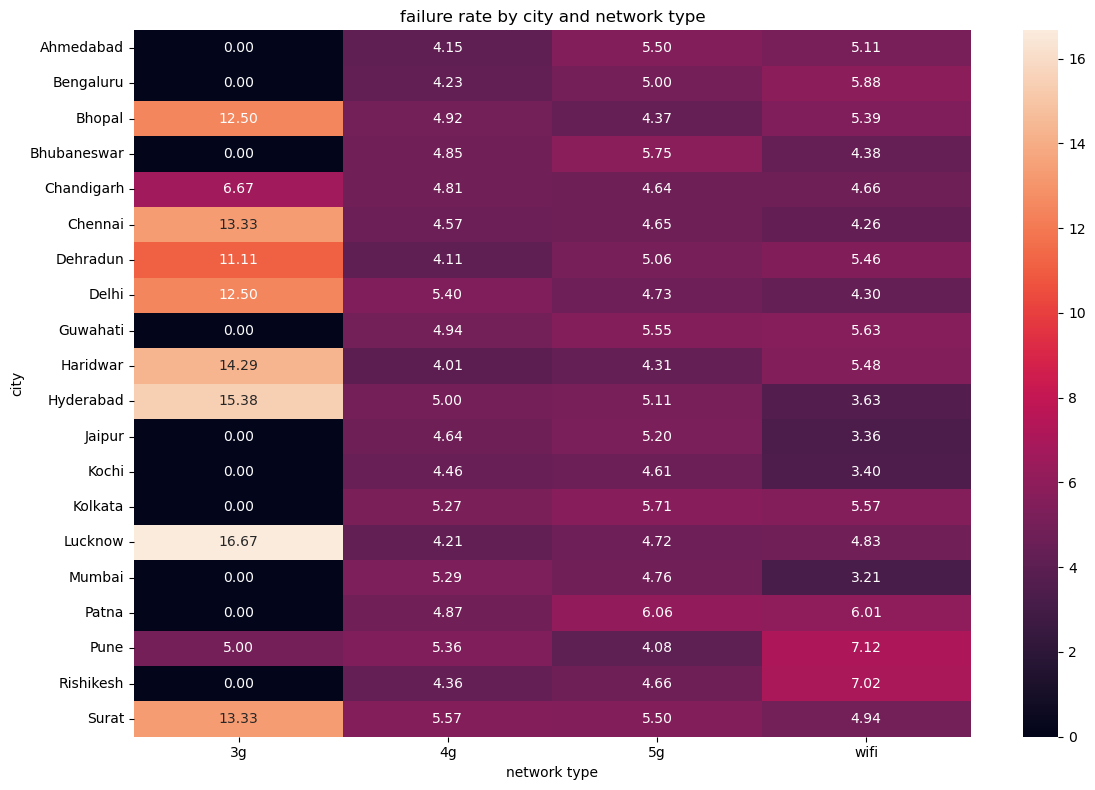

In [146]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    city_network_pivot,
    annot=True,
    fmt=".2f"
)

plt.title("failure rate by city and network type")
plt.xlabel("network type")
plt.ylabel("city")

plt.tight_layout()
plt.show()

In [147]:
city_network_analysis.sort_values(
    "failure_rate",
    ascending=False
).head(15)

,city,network_type,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate
56,Lucknow,3g,18,15,3,403551.09,16.67
40,Hyderabad,3g,13,11,2,282979.02,15.38
36,Haridwar,3g,7,6,1,115332.92,14.29
20,Chennai,3g,15,13,2,427005.22,13.33
76,Surat,3g,15,13,2,227569.33,13.33
8,Bhopal,3g,16,14,2,429714.71,12.50
28,Delhi,3g,8,7,1,192550.32,12.50
24,Dehradun,3g,18,16,2,415324.10,11.11
71,Pune,wifi,267,248,19,6949860.07,7.12
75,Rishikesh,wifi,285,265,20,6709222.07,7.02


In [148]:
city_network_analysis.sort_values(
    "total_transactions",
    ascending=False
).head(15)

,city,network_type,total_transactions,successful_transactions,failed_transactions,total_transaction_value,failure_rate
61,Mumbai,4g,3079,2916,163,77344640.31,5.29
25,Dehradun,4g,3068,2942,126,76687473.34,4.11
41,Hyderabad,4g,3059,2906,153,76863409.11,5.00
65,Patna,4g,3057,2908,149,76454400.33,4.87
53,Kolkata,4g,3053,2892,161,76978824.31,5.27
1,Ahmedabad,4g,3037,2911,126,75291781.56,4.15
73,Rishikesh,4g,3026,2894,132,76472197.55,4.36
57,Lucknow,4g,3020,2893,127,76014441.31,4.21
37,Haridwar,4g,2993,2873,120,75733569.48,4.01
9,Bhopal,4g,2968,2822,146,73923926.94,4.92


In [149]:
#Multi dimensional risk analysis
risk_analysis = (
    df.groupby(
        [
            "bank_name",
            "city",
            "payment_channel",
            "network_type"
        ]
    )
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("transaction_status", lambda x: (x == "failed").sum()),
        successful_transactions=("transaction_status", lambda x: (x == "success").sum()),
        total_transaction_value=("transaction_amount", "sum")
    )
    .reset_index()
)

risk_analysis["failure_rate"] = (
    risk_analysis["failed_transactions"]
    / risk_analysis["total_transactions"]
    * 100
).round(2)

risk_analysis["success_rate"] = (
    risk_analysis["successful_transactions"]
    / risk_analysis["total_transactions"]
    * 100
).round(2)

risk_analysis.head()

,bank_name,city,payment_channel,network_type,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
0,AU Small Finance Bank,Ahmedabad,collect_request,4g,44,2,42,1195189.86,4.55,95.45
1,AU Small Finance Bank,Ahmedabad,collect_request,5g,31,2,29,791846.70,6.45,93.55
2,AU Small Finance Bank,Ahmedabad,collect_request,wifi,7,0,7,217153.59,0.00,100.00
3,AU Small Finance Bank,Ahmedabad,qr,4g,44,2,42,1111397.93,4.55,95.45
4,AU Small Finance Bank,Ahmedabad,qr,5g,37,3,34,749393.31,8.11,91.89


In [150]:
risk_filtered = risk_analysis[
    risk_analysis["total_transactions"] >= 50
].copy()

risk_filtered = risk_filtered.sort_values(
    "failure_rate",
    ascending=False
)

risk_filtered.head(20)

,bank_name,city,payment_channel,network_type,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
1930,IDFC FIRST Bank,Kochi,collect_request,4g,52,8,44,1286301.04,15.38,84.62
2930,State Bank of India,Hyderabad,upi_app,4g,50,7,43,1168764.27,14.00,86.00
1396,HDFC Bank,Hyderabad,qr,4g,59,8,51,1335253.67,13.56,86.44
2186,IndusInd Bank,Jaipur,upi_id,4g,60,8,52,1544286.00,13.33,86.67
1661,ICICI Bank,Jaipur,upi_app,4g,53,7,46,1226405.25,13.21,86.79
955,Canara Bank,Mumbai,collect_request,4g,61,8,53,1587695.67,13.11,86.89
3244,Ujjivan Small Finance Bank,Lucknow,upi_id,4g,55,7,48,1347312.59,12.73,87.27
1362,HDFC Bank,Delhi,upi_app,4g,56,7,49,1249584.74,12.50,87.50
2992,State Bank of India,Mumbai,qr,4g,65,8,57,1726042.13,12.31,87.69
3281,Ujjivan Small Finance Bank,Pune,upi_id,4g,57,7,50,1562240.88,12.28,87.72


In [151]:
high_risk_combinations = risk_filtered[
    risk_filtered["failure_rate"] >= 15
].copy()

high_risk_combinations.head(20)

,bank_name,city,payment_channel,network_type,total_transactions,failed_transactions,successful_transactions,total_transaction_value,failure_rate,success_rate
1930,IDFC FIRST Bank,Kochi,collect_request,4g,52,8,44,1286301.04,15.38,84.62


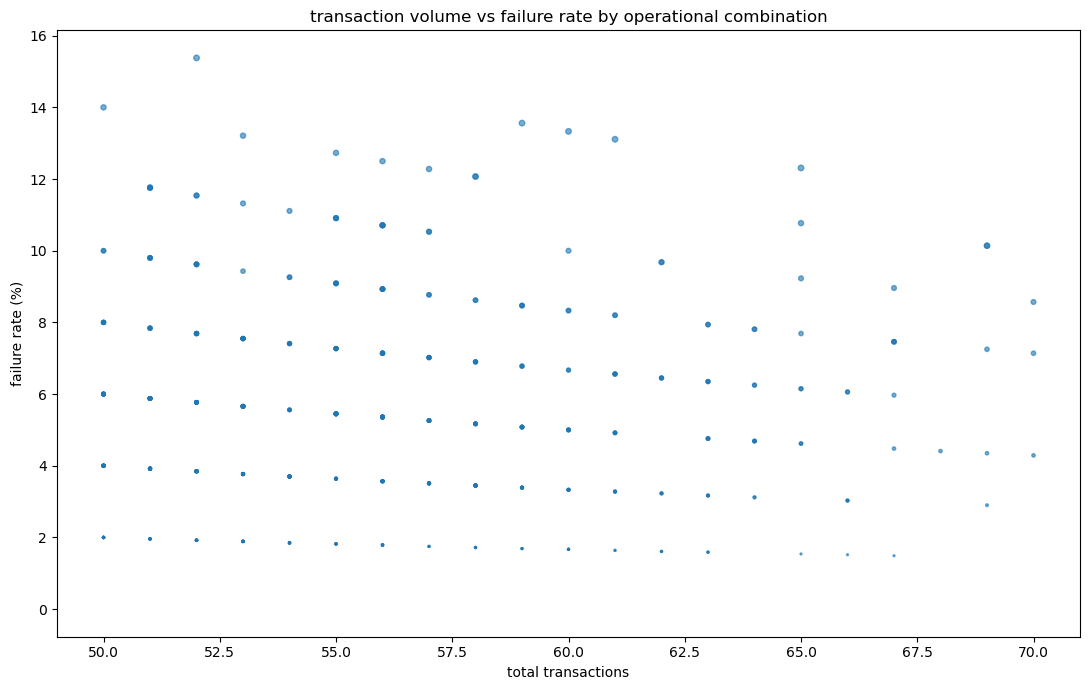

In [152]:
plt.figure(figsize=(11, 7))

plt.scatter(
    risk_filtered["total_transactions"],
    risk_filtered["failure_rate"],
    s=risk_filtered["failed_transactions"] * 2,
    alpha=0.6
)

plt.xlabel("total transactions")
plt.ylabel("failure rate (%)")
plt.title("transaction volume vs failure rate by operational combination")

plt.tight_layout()
plt.show()

In [153]:
risk_filtered[
    [
        "bank_name",
        "city",
        "payment_channel",
        "network_type",
        "total_transactions",
        "failed_transactions",
        "failure_rate",
        "success_rate"
    ]
].head(20)

,bank_name,city,payment_channel,network_type,total_transactions,failed_transactions,failure_rate,success_rate
1930,IDFC FIRST Bank,Kochi,collect_request,4g,52,8,15.38,84.62
2930,State Bank of India,Hyderabad,upi_app,4g,50,7,14.00,86.00
1396,HDFC Bank,Hyderabad,qr,4g,59,8,13.56,86.44
2186,IndusInd Bank,Jaipur,upi_id,4g,60,8,13.33,86.67
1661,ICICI Bank,Jaipur,upi_app,4g,53,7,13.21,86.79
955,Canara Bank,Mumbai,collect_request,4g,61,8,13.11,86.89
3244,Ujjivan Small Finance Bank,Lucknow,upi_id,4g,55,7,12.73,87.27
1362,HDFC Bank,Delhi,upi_app,4g,56,7,12.50,87.50
2992,State Bank of India,Mumbai,qr,4g,65,8,12.31,87.69
3281,Ujjivan Small Finance Bank,Pune,upi_id,4g,57,7,12.28,87.72


In [154]:
print("total combinations:", len(risk_analysis))
print("combinations with 50+ transactions:", len(risk_filtered))
print("high-risk combinations:", len(high_risk_combinations))

total combinations: 3836
combinations with 50+ transactions: 593
high-risk combinations: 1
